# 02 · Red neuronal en PyTorch (v2): demanda de bicis por estación cada 15 minutos

**Entrada:** estación + fecha/hora (slot de 15 min) + calendario + clima.
**Salida:** 4 valores por estación → `salidas_classic`, `salidas_electric`, `llegadas_classic`, `llegadas_electric` (más sus totales y el flujo neto).

**Diseño:**
- **Formato largo:** cada ejemplo es una pareja *(estación, slot)*. La red aprende un **embedding por estación**, así que un solo modelo sirve para todas y escala al agregar más meses.
- **Sin lags:** el modelo puede predecir cualquier fecha con sólo conocer el calendario y el pronóstico del clima.
- **Poisson loss:** los objetivos son conteos pequeños con muchos ceros; la red predice la **tasa esperada** λ (en escala log).
- **Splits temporales:** train → val → test en orden cronológico, sin mezclar el futuro con el pasado.
- **Baselines honestos:** el modelo se compara contra el "promedio histórico por estación × día de semana × slot", que es difícil de superar.

### Cambios de la versión 2 (para bajar la val loss)
1. **GPU en Mac (MPS)**, además de CUDA, en lugar de entrenar en CPU.
2. **Diagnóstico previo:** la val loss de varios baselines con la *misma* Poisson loss, para saber si 0.35 es bueno o malo.
3. **Menos memorización del clima:** se quitan variables redundantes (sensación térmica, lluvia duplicada, nieve, nubosidad) y se agrega **ruido gaussiano al clima durante el entrenamiento**.
4. **Nueva feature de clima:** lluvia acumulada de las 2 horas previas (la gente tarda en volver a salir después de llover). No es un lag de demanda; se obtiene del pronóstico.
5. **Perfil diario explícito por estación:** un término de factorización `estación × (laborable/libre, slot)` que modela directamente la curva diaria de cada estación; el MLP sólo aprende las desviaciones (clima, festivos).
6. **Más regularización:** dropout en embeddings y capas, weight decay real, red más pequeña.
7. **Entrenamiento más estable:** warmup + cosine decay y **EMA de los pesos** (promedio móvil), que suaviza mucho la val loss.

> Requisitos: ejecutar antes el notebook 01. `pip install torch pandas pyarrow numpy matplotlib seaborn requests` (para CUDA, instala torch desde pytorch.org con tu versión de CUDA).

## 1. Imports, configuración y dispositivo

In [1]:
import copy
import json
import math
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import requests
import torch
import torch.nn as nn

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (13, 5)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif getattr(torch.backends, 'mps', None) is not None and torch.backends.mps.is_available():
    DEVICE = torch.device('mps')          # GPU de Apple Silicon (M1/M2/M3/M4)
else:
    DEVICE = torch.device('cpu')
    torch.set_num_threads(max(1, __import__('os').cpu_count() - 1))
print('torch', torch.__version__, '| dispositivo:', DEVICE)
if DEVICE.type == 'cpu':
    print('⚠️ Entrenando en CPU. En Mac con chip Apple verifica que tu torch tenga MPS: torch.backends.mps.is_available()')
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0),
          f'| memoria: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

torch 2.14.1 | dispositivo: mps


In [2]:
# ───────────────────────── CONFIGURACIÓN ─────────────────────────
DATA_DIR  = Path('data_procesada')
MODEL_DIR = Path('modelos')
MODEL_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42

# Splits temporales: los últimos TEST_DIAS días → test; los VAL_DIAS anteriores → validación; el resto → train
VAL_DIAS  = 14
TEST_DIAS = 14

CFG = dict(
    emb_estacion = 32,          # dimensión del embedding por estación
    emb_slot     = 16,          # embedding del slot del día (0..95)
    emb_dow      = 4,           # embedding del día de la semana
    emb_clima    = 4,           # embedding del grupo de weather_code
    rango_perfil = 16,          # rango del término de factorización estación × (tipo de día, slot)
    ocultas      = [256, 128],  # red más pequeña: menos capacidad para memorizar días
    dropout      = 0.25,
    dropout_emb  = 0.10,        # dropout sobre los embeddings concatenados
    ruido_clima  = 0.15,        # ruido gaussiano (en desviaciones estándar) al clima en train
    lr           = 1e-3,
    weight_decay = 1e-2,        # AdamW: decaimiento real (no se aplica a sesgos ni LayerNorm)
    batch        = 16384,
    batch_eval   = 65536,
    epocas       = 20,          # tope; el cosine decay se ajusta a este número
    warmup_epocas = 1,
    paciencia    = 4,           # early stopping sobre la val loss del modelo EMA
    ema_decay    = 0.999,
    fraccion_epoca = 1.0,       # < 1.0 usa una muestra aleatoria del train en cada época (más rápido)
    usar_amp     = True,        # mixed precision (sólo CUDA)
)

def fijar_semilla(seed):
    np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
fijar_semilla(SEED)

## 2. Cargar los datos del notebook 01

In [3]:
estaciones = pd.read_parquet(DATA_DIR / 'estaciones.parquet').sort_values('station_idx').reset_index(drop=True)
slots      = pd.read_parquet(DATA_DIR / 'slots.parquet').sort_values('slot_idx').reset_index(drop=True)
demanda    = pd.read_parquet(DATA_DIR / 'demanda_15min.parquet')
META       = json.loads((DATA_DIR / 'metadata.json').read_text())

TARGETS = ['salidas_classic', 'salidas_electric', 'llegadas_classic', 'llegadas_electric']
N_EST, N_SLOTS = len(estaciones), len(slots)
assert (slots['slot_idx'].values == np.arange(N_SLOTS)).all()
assert (estaciones['station_idx'].values == np.arange(N_EST)).all()

print(f'Estaciones: {N_EST:,} | slots: {N_SLOTS:,} ({N_SLOTS // 96} días) | filas: {len(demanda):,}')
print(f'Periodo: {slots.timestamp.min()} → {slots.timestamp.max()}')
display(demanda.head())

Estaciones: 2,461 | slots: 8,832 (92 días) | filas: 20,865,600
Periodo: 2026-07-01 00:00:00 → 2026-09-30 23:45:00


,station_idx,slot_idx,salidas_classic,salidas_electric,llegadas_classic,llegadas_electric,salidas_total,llegadas_total
0,0,0,0,4,0,1,4,1
1,0,1,0,0,1,0,0,1
2,0,2,0,2,0,1,2,1
3,0,3,0,0,0,0,0,0
4,0,4,0,0,0,0,0,0


## 3. Ingeniería de features
Todas las transformaciones viven en **una sola función** (`preparar_features`) que se usa igual para entrenar y para predecir fechas nuevas. Así se evita que el modelo vea features distintas en producción.

| Tipo | Features |
|---|---|
| Categóricas (embedding) | estación, slot del día (0–95), día de la semana, grupo de clima |
| Calendario | seno/coseno del slot, seno/coseno del día, fin de semana, festivo, día libre |
| Clima (estandarizado) | temperatura, humedad, viento, log(1+precipitación), log(1+lluvia de las 2 h previas), llueve |

In [4]:
VARS_CLIMA = META['vars_clima']

def grupo_weather_code(wc):
    # Agrupa los códigos WMO de Open-Meteo en 7 categorías
    wc = np.nan_to_num(np.asarray(wc, dtype=float), nan=0)
    return np.select([wc <= 1, wc <= 3, wc <= 48, wc <= 67, wc <= 77, wc <= 86],
                     [0, 1, 2, 3, 4, 5], default=6).astype(np.int64)
N_GRUPOS_CLIMA = 7

CAT_COLS = ['slot_dia', 'dia_semana', 'wc_grupo']
# v2: clima reducido a lo que realmente explica la demanda (menos variables = menos memorización de días)
CONT_COLS = ['slot_sin', 'slot_cos', 'dow_sin', 'dow_cos', 'es_fin_semana', 'es_festivo', 'dia_libre',
             'temperature_2m', 'relative_humidity_2m', 'wind_speed_10m', 'precip_log', 'precip_prev_log', 'llueve']
ESCALAR = ['temperature_2m', 'relative_humidity_2m', 'wind_speed_10m', 'precip_log', 'precip_prev_log']

def agregar_lluvia_previa(clima, slots_previos=8):
    # Lluvia acumulada (mm) en las 2 h anteriores al slot. `clima` debe estar ordenado cada 15 min.
    c = clima.copy()
    c['precip_prev2h'] = (c['precipitation'].shift(1).rolling(slots_previos, min_periods=1).sum() / 4).fillna(0)
    return c

slots = agregar_lluvia_previa(slots)

def preparar_features(s):
    # s: DataFrame con timestamp, banderas de calendario y las variables de clima
    s = s.copy()
    ts = pd.to_datetime(s['timestamp'])
    s['slot_dia']   = (ts.dt.hour * 4 + ts.dt.minute // 15).astype(np.int64)
    s['dia_semana'] = ts.dt.dayofweek.astype(np.int64)
    s['slot_sin'] = np.sin(2 * np.pi * s['slot_dia'] / 96); s['slot_cos'] = np.cos(2 * np.pi * s['slot_dia'] / 96)
    s['dow_sin']  = np.sin(2 * np.pi * s['dia_semana'] / 7); s['dow_cos'] = np.cos(2 * np.pi * s['dia_semana'] / 7)
    s['es_fin_semana'] = (s['dia_semana'] >= 5).astype(np.int8)
    s['dia_libre']  = ((s['es_fin_semana'] == 1) | (s['es_festivo'] == 1)).astype(np.int8)
    s['precip_log'] = np.log1p(s['precipitation'].clip(lower=0))
    s['rain_log']   = np.log1p(s['rain'].clip(lower=0))
    s['snow_log']   = np.log1p(s['snowfall'].clip(lower=0))
    s['precip_prev_log'] = np.log1p(s['precip_prev2h'].clip(lower=0))
    s['llueve']     = (s['precipitation'] >= 0.1).astype(np.int8)
    s['wc_grupo']   = grupo_weather_code(s['weather_code'])
    return s

slots_f = preparar_features(slots)
display(slots_f[['timestamp'] + CAT_COLS + CONT_COLS].head())

,timestamp,slot_dia,dia_semana,wc_grupo,slot_sin,slot_cos,dow_sin,dow_cos,es_fin_semana,es_festivo,dia_libre,temperature_2m,relative_humidity_2m,wind_speed_10m,precip_log,precip_prev_log,llueve
0,2026-07-01 00:00:00,0,2,0,0.000000,1.000000,0.974928,-0.222521,0,0,0,26.799999,52.00,12.90,0.0,0.0,0
1,2026-07-01 00:15:00,1,2,0,0.065403,0.997859,0.974928,-0.222521,0,0,0,26.625000,52.25,12.55,0.0,0.0,0
2,2026-07-01 00:30:00,2,2,0,0.130526,0.991445,0.974928,-0.222521,0,0,0,26.450001,52.50,12.20,0.0,0.0,0
3,2026-07-01 00:45:00,3,2,0,0.195090,0.980785,0.974928,-0.222521,0,0,0,26.275000,52.75,11.85,0.0,0.0,0
4,2026-07-01 01:00:00,4,2,0,0.258819,0.965926,0.974928,-0.222521,0,0,0,26.100000,53.00,11.50,0.0,0.0,0


## 4. Splits temporales: train / validación / test

,min,max,dias,filas,bicis_salen
split,,,,,
train,2026-07-01,2026-09-02,64,14450496,10488253
val,2026-09-03,2026-09-16,14,3222048,2530803
test,2026-09-17,2026-09-30,14,3193056,2149710


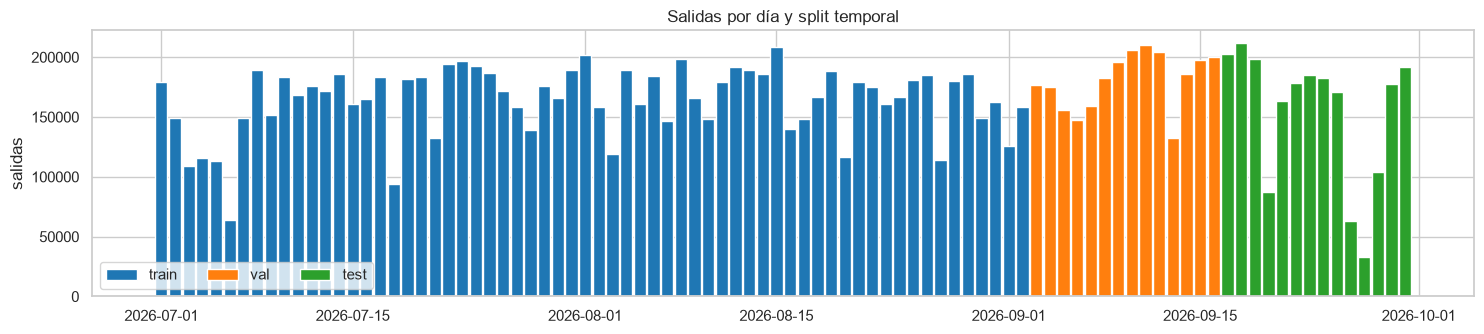

In [5]:
fechas = np.sort(slots_f['fecha'].unique())
assert len(fechas) > VAL_DIAS + TEST_DIAS + 7, 'Muy pocos días para estos splits'
f_test = fechas[-TEST_DIAS:]
f_val  = fechas[-(TEST_DIAS + VAL_DIAS):-TEST_DIAS]
slots_f['split'] = np.where(slots_f['fecha'].isin(f_test), 'test',
                    np.where(slots_f['fecha'].isin(f_val), 'val', 'train'))

split_fila = slots_f['split'].values[demanda['slot_idx'].values]
resumen = (pd.DataFrame({'split': split_fila, 'salidas': demanda[TARGETS[:2]].sum(axis=1).values})
           .groupby('split').agg(filas=('salidas', 'size'), bicis_salen=('salidas', 'sum')))
rangos = slots_f.groupby('split')['fecha'].agg(['min', 'max', 'nunique']).rename(columns={'nunique': 'dias'})
display(rangos.join(resumen).loc[['train', 'val', 'test']])

fig, ax = plt.subplots(figsize=(15, 3.5))
diario = slots_f.assign(bicis=np.bincount(demanda['slot_idx'], weights=demanda[TARGETS[:2]].sum(axis=1), minlength=N_SLOTS))
diario = diario.groupby(['fecha', 'split'])['bicis'].sum().unstack('split')
for sp, col in [('train', 'tab:blue'), ('val', 'tab:orange'), ('test', 'tab:green')]:
    ax.bar(diario.index, diario[sp].fillna(0), color=col, label=sp, width=0.9)
ax.legend(loc='lower left', ncol=3)
ax.set(title='Salidas por día y split temporal', xlabel='', ylabel='salidas')
plt.tight_layout(); plt.show()

## 5. Estandarización (ajustada **sólo** con train) y tensores
Las features por slot se guardan una sola vez en una tabla `[n_slots, n_features]`. Cada batch sólo carga los índices *(estación, slot)* y busca sus features. Esto es mucho más eficiente en memoria que replicar el clima en millones de filas. Si la GPU tiene memoria suficiente, **todo el dataset vive en la GPU** y el entrenamiento no tiene cuellos de botella de transferencia.

In [6]:
es_train_slot = slots_f['split'].values == 'train'
MU = slots_f.loc[es_train_slot, ESCALAR].mean()
SD = slots_f.loc[es_train_slot, ESCALAR].std().replace(0, 1).fillna(1)

def matriz_features(s_f):
    X = s_f[CONT_COLS].astype(np.float32).copy()
    X[ESCALAR] = (X[ESCALAR] - MU[ESCALAR].values) / SD[ESCALAR].values
    return (torch.tensor(X.values, dtype=torch.float32),
            torch.tensor(s_f['slot_dia'].values, dtype=torch.long),
            torch.tensor(s_f['dia_semana'].values, dtype=torch.long),
            torch.tensor(s_f['wc_grupo'].values, dtype=torch.long),
            torch.tensor(s_f['dia_libre'].values, dtype=torch.long))

XC, SLOTD, DOW, WC, LIBRE = matriz_features(slots_f)
ST = torch.tensor(demanda['station_idx'].values, dtype=torch.long)
SL = torch.tensor(demanda['slot_idx'].values, dtype=torch.long)
Yt = torch.tensor(demanda[TARGETS].values, dtype=torch.float32)

bytes_aprox = ST.numel() * 8 * 2 + Yt.numel() * 4 + XC.numel() * 4
DATOS_EN_GPU = False
if DEVICE.type == 'cuda':
    libre, _ = torch.cuda.mem_get_info()
    DATOS_EN_GPU = bytes_aprox < 0.5 * libre
elif DEVICE.type == 'mps':
    DATOS_EN_GPU = True        # memoria unificada en Apple Silicon
DATA_DEVICE = DEVICE if DATOS_EN_GPU else torch.device('cpu')
XC, SLOTD, DOW, WC, LIBRE, ST, SL, Yt = [t.to(DATA_DEVICE) for t in (XC, SLOTD, DOW, WC, LIBRE, ST, SL, Yt)]

IDX = {k: torch.nonzero(torch.tensor(split_fila == k), as_tuple=True)[0].to(DATA_DEVICE) for k in ['train', 'val', 'test']}
print(f'Datos: {bytes_aprox / 1e9:.2f} GB → en {DATA_DEVICE} | ' +
      ' | '.join(f'{k}: {len(v):,} filas' for k, v in IDX.items()))
print('Features continuas:', len(CONT_COLS), '| categóricas:', CAT_COLS + ['station_idx'])

Datos: 0.67 GB → en mps | train: 14,450,496 filas | val: 3,222,048 filas | test: 3,193,056 filas
Features continuas: 13 | categóricas: ['slot_dia', 'dia_semana', 'wc_grupo', 'station_idx']


In [7]:
def iterar_batches(idx, batch, barajar):
    if barajar:
        idx = idx[torch.randperm(len(idx), device=idx.device)]
    for i in range(0, len(idx), batch):
        yield idx[i:i + batch]

def obtener_batch(b):
    s, t = ST[b], SL[b]
    salida = (s, SLOTD[t], DOW[t], WC[t], XC[t], LIBRE[t], Yt[b])
    return [x.to(DEVICE, non_blocking=True) for x in salida]

## 5b. Diagnóstico: ¿qué tan buena es una val loss de 0.35?
La Poisson loss con `full=False` **no tiene su mínimo en 0**: incluso un modelo perfecto conserva el ruido aleatorio de los conteos. Por eso, antes de entrenar, se calcula la val loss de varios baselines con **exactamente la misma función**:

| Referencia | Qué representa |
|---|---|
| Media global | Lo peor razonable |
| Media por estación | Sabe cuánto mueve cada estación, pero no a qué hora |
| Estación × día de semana × slot | El "sentido común" del operador (~9 semanas de muestras por celda) |
| Estación × laborable/libre × slot | Igual, pero con más muestras por celda (menos ruido) |
| *Oráculo (con fuga)* | La misma tabla calculada **con los datos de validación**. No es un modelo válido; es una referencia de qué tan bajo se puede llegar aproximadamente |

La red debe quedar claramente **por debajo de los baselines** y acercarse al oráculo. También se muestra el **cambio de nivel** de la demanda entre train y validación.

In [8]:
def poisson_nll_np(y, p):
    # Igual que nn.PoissonNLLLoss(log_input=True, full=False): media de (λ - y·log λ)
    p = np.clip(p, 1e-8, None)
    return float(np.mean(p - y * np.log(p)))

st_all, sl_all = demanda['station_idx'].values, demanda['slot_idx'].values
Y_all = demanda[TARGETS].values.astype(np.float64)
dow_s, sd_s, libre_s = slots_f['dia_semana'].values, slots_f['slot_dia'].values, slots_f['dia_libre'].values
i_tr, i_va = np.nonzero(split_fila == 'train')[0], np.nonzero(split_fila == 'val')[0]
y_va = Y_all[i_va]

def media_por_clave(clave, fit_idx, eval_idx, n_claves, respaldo):
    suma = np.zeros((n_claves, 4)); cnt = np.zeros(n_claves)
    np.add.at(suma, clave[fit_idx], Y_all[fit_idx]); np.add.at(cnt, clave[fit_idx], 1)
    k = clave[eval_idx]
    return np.where(cnt[k][:, None] > 0, suma[k] / np.maximum(cnt[k], 1)[:, None], respaldo)

p_glob = np.broadcast_to(Y_all[i_tr].mean(0), y_va.shape)
k_est = st_all
p_est = media_por_clave(k_est, i_tr, i_va, N_EST, p_glob)
k_dow = (st_all * 7 + dow_s[sl_all]) * 96 + sd_s[sl_all]
p_dow = media_por_clave(k_dow, i_tr, i_va, N_EST * 7 * 96, p_est)
k_lib = (st_all * 2 + libre_s[sl_all]) * 96 + sd_s[sl_all]
p_lib = media_por_clave(k_lib, i_tr, i_va, N_EST * 2 * 96, p_est)
p_orc = media_por_clave(k_lib, i_va, i_va, N_EST * 2 * 96, p_est)

DIAG = pd.DataFrame({'referencia': ['Media global', 'Media por estación', 'Estación × día × slot',
                                    'Estación × laborable/libre × slot', 'Oráculo (con fuga, sólo referencia)'],
                     'val_poisson_nll': [poisson_nll_np(y_va, p) for p in [p_glob, p_est, p_dow, p_lib, p_orc]]})
display(DIAG.round(5))

dias_tr = slots_f.loc[slots_f.split == 'train', 'fecha'].nunique()
dias_va = slots_f.loc[slots_f.split == 'val', 'fecha'].nunique()
nivel_tr = Y_all[i_tr].sum() / dias_tr; nivel_va = y_va.sum() / dias_va
print(f'Cambio de nivel: train {nivel_tr:,.0f} movimientos/día vs val {nivel_va:,.0f} → {nivel_va / nivel_tr - 1:+.1%}')
p_lib_aj = p_lib * (nivel_va / nivel_tr)
print(f'Baseline laborable/libre ajustado al nivel de val: {poisson_nll_np(y_va, p_lib_aj):.5f} '
      f'(cuánto se gana si se conociera el nivel general de septiembre)')

,referencia,val_poisson_nll
0,Media global,0.72057
1,Media por estación,0.47939
2,Estación × día × slot,0.71910
3,Estación × laborable/libre × slot,0.44549
4,"Oráculo (con fuga, sólo referencia)",0.26480


Cambio de nivel: train 327,735 movimientos/día vs val 361,517 → +10.3%
Baseline laborable/libre ajustado al nivel de val: 0.44448 (cuánto se gana si se conociera el nivel general de septiembre)


## 6. Modelo
```
estación ─► Embedding(32) ┐
slot_dia ─► Embedding(16) ├─► concat ─► Dropout ─► [Linear → LayerNorm → GELU → Dropout] × 2 ─► Linear(4) ─┐
día      ─► Embedding(4)  │                                                                                 │
clima    ─► Embedding(4)  │                                                                                 ├─► log λ (4 salidas)
continuas (13) ───────────┘                                                                                 │
perfil diario: ⟨u_estación , v_(laborable/libre, slot)⟩  (rango 16, por objetivo) ──────────────────────────┤
sesgo propio de cada estación (4) ──────────────────────────────────────────────────────────────────────────┘
```
- La salida es **log λ**, la tasa esperada de bicis en el slot. `PoissonNLLLoss(log_input=True)` trabaja directamente con eso.
- **Perfil diario factorizado:** cada estación tiene un vector `u` y cada combinación *(tipo de día, slot)* un vector `v`. Su producto punto da la curva diaria propia de la estación (por ejemplo, "se vacía a las 8:00 entre semana"). Es la señal principal del problema y así se modela directamente, sin depender de que el MLP la descubra.
- El MLP aprende las **desviaciones**: clima, festivos y diferencias entre días.
- Durante el entrenamiento se suma **ruido gaussiano al clima**, para que la red no use los valores exactos de temperatura o humedad como identificador de cada día.

In [9]:
class DemandaNet(nn.Module):
    def __init__(self, n_est, n_cont, cfg, media_targets, idx_clima):
        super().__init__()
        self.cfg = cfg
        self.register_buffer('idx_clima', torch.tensor(idx_clima, dtype=torch.long), persistent=False)
        self.emb_est  = nn.Embedding(n_est, cfg['emb_estacion'])
        self.emb_slot = nn.Embedding(96, cfg['emb_slot'])
        self.emb_dow  = nn.Embedding(7, cfg['emb_dow'])
        self.emb_wc   = nn.Embedding(N_GRUPOS_CLIMA, cfg['emb_clima'])
        self.sesgo_est = nn.Embedding(n_est, 4)
        R = cfg['rango_perfil']
        self.perfil_est = nn.Embedding(n_est, 4 * R)
        self.perfil_t   = nn.Embedding(2 * 96, 4 * R)          # (laborable/libre) × slot
        nn.init.zeros_(self.sesgo_est.weight)
        for e in (self.emb_est, self.emb_slot, self.emb_dow, self.emb_wc):
            nn.init.normal_(e.weight, std=0.05)
        nn.init.normal_(self.perfil_est.weight, std=0.1)
        nn.init.normal_(self.perfil_t.weight, std=0.1)

        dim = cfg['emb_estacion'] + cfg['emb_slot'] + cfg['emb_dow'] + cfg['emb_clima'] + n_cont
        self.drop_emb = nn.Dropout(cfg['dropout_emb'])
        capas = []
        for h in cfg['ocultas']:
            capas += [nn.Linear(dim, h), nn.LayerNorm(h), nn.GELU(), nn.Dropout(cfg['dropout'])]
            dim = h
        self.mlp = nn.Sequential(*capas)
        self.salida = nn.Linear(dim, 4)
        with torch.no_grad():
            self.salida.weight.mul_(0.1)
            self.salida.bias.copy_(torch.log(media_targets.clamp(min=1e-4)))

    def forward(self, est, slot_dia, dow, wc, xc, dia_libre):
        if self.training and self.cfg['ruido_clima'] > 0:
            ruido = torch.zeros_like(xc)
            ruido[:, self.idx_clima] = torch.randn(xc.shape[0], len(self.idx_clima), device=xc.device) * self.cfg['ruido_clima']
            xc = xc + ruido
        z = torch.cat([self.emb_est(est), self.emb_slot(slot_dia), self.emb_dow(dow), self.emb_wc(wc), xc], dim=1)
        R = self.cfg['rango_perfil']
        u = self.perfil_est(est).view(-1, 4, R)
        v = self.perfil_t(dia_libre * 96 + slot_dia).view(-1, 4, R)
        perfil = (u * v).sum(-1)
        log_lambda = self.salida(self.mlp(self.drop_emb(z))) + perfil + self.sesgo_est(est)
        return log_lambda.clamp(-15, 10)

media_train = Yt[IDX['train']].mean(dim=0).cpu()
IDX_CLIMA = [CONT_COLS.index(c) for c in ESCALAR]
modelo = DemandaNet(N_EST, len(CONT_COLS), CFG, media_train, IDX_CLIMA).to(DEVICE)
n_param = sum(p.numel() for p in modelo.parameters())
print(modelo)
print(f'\nParámetros entrenables: {n_param:,}')

DemandaNet(
  (emb_est): Embedding(2461, 32)
  (emb_slot): Embedding(96, 16)
  (emb_dow): Embedding(7, 4)
  (emb_wc): Embedding(7, 4)
  (sesgo_est): Embedding(2461, 4)
  (perfil_est): Embedding(2461, 64)
  (perfil_t): Embedding(192, 64)
  (drop_emb): Dropout(p=0.1, inplace=False)
  (mlp): Sequential(
    (0): Linear(in_features=69, out_features=256, bias=True)
    (1): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
    (6): GELU(approximate='none')
    (7): Dropout(p=0.25, inplace=False)
  )
  (salida): Linear(in_features=128, out_features=4, bias=True)
)

Parámetros entrenables: 312,080


## 7. Entrenamiento: warmup + cosine, EMA de pesos y early stopping

In [10]:
class EMA:
    # Promedio móvil exponencial de los pesos. El decaimiento arranca bajo y sube hasta `decay`,
    # para que la EMA no quede atada a los pesos iniciales al inicio del entrenamiento.
    def __init__(self, red, decay):
        self.module = copy.deepcopy(red).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.decay, self.n = decay, 0
    @torch.no_grad()
    def update_parameters(self, red):
        self.n += 1
        d = min(self.decay, (1 + self.n) / (10 + self.n))
        for pe, pm in zip(self.module.parameters(), red.parameters()):
            pe.lerp_(pm.detach(), 1 - d)

criterio = nn.PoissonNLLLoss(log_input=True, full=False, reduction='mean')

# Weight decay sólo en matrices de pesos (no en sesgos, LayerNorm ni sesgo por estación)
con_wd, sin_wd = [], []
for nombre, p in modelo.named_parameters():
    (sin_wd if (p.ndim < 2 or 'sesgo_est' in nombre or 'norm' in nombre.lower()) else con_wd).append(p)
optim = torch.optim.AdamW([{'params': con_wd, 'weight_decay': CFG['weight_decay']},
                           {'params': sin_wd, 'weight_decay': 0.0}], lr=CFG['lr'])

n_train_ep = int(len(IDX['train']) * CFG['fraccion_epoca'])
pasos_epoca = math.ceil(n_train_ep / CFG['batch'])
pasos_total = pasos_epoca * CFG['epocas']
pasos_warmup = pasos_epoca * CFG['warmup_epocas']
def factor_lr(paso):
    if paso < pasos_warmup:
        return (paso + 1) / pasos_warmup
    prog = (paso - pasos_warmup) / max(1, pasos_total - pasos_warmup)
    return 0.05 + 0.95 * 0.5 * (1 + math.cos(math.pi * min(prog, 1.0)))
sched = torch.optim.lr_scheduler.LambdaLR(optim, factor_lr)

# EMA: promedio móvil exponencial de los pesos; suele generalizar mejor que los pesos "crudos"
ema = EMA(modelo, CFG['ema_decay'])

USAR_AMP = CFG['usar_amp'] and DEVICE.type == 'cuda'
AMP_DTYPE = torch.bfloat16 if (USAR_AMP and torch.cuda.is_bf16_supported()) else torch.float16
scaler = torch.amp.GradScaler('cuda', enabled=USAR_AMP and AMP_DTYPE == torch.float16)

def adelante(b, red=None):
    red = modelo if red is None else red
    est, sd, dw, wc, xc, lb, y = obtener_batch(b)
    with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USAR_AMP):
        out = red(est, sd, dw, wc, xc, lb)
    return out.float(), y

@torch.no_grad()
def evaluar_loss(idx, red):
    red.eval()
    total = torch.zeros((), device=DEVICE); n = 0
    for b in iterar_batches(idx, CFG['batch_eval'], False):
        out, y = adelante(b, red)
        total += criterio(out, y) * len(b); n += len(b)
    return (total / n).item()

print(f'{pasos_epoca:,} pasos por época | warmup {pasos_warmup:,} pasos | máximo {CFG["epocas"]} épocas')
historial, mejor_val, mejor_estado, sin_mejora = [], math.inf, None, 0
for epoca in range(1, CFG['epocas'] + 1):
    t0 = time.time(); modelo.train()
    idx_ep = IDX['train']
    if CFG['fraccion_epoca'] < 1.0:
        idx_ep = idx_ep[torch.randperm(len(idx_ep), device=idx_ep.device)[:n_train_ep]]
    suma = torch.zeros((), device=DEVICE); n = 0
    for b in iterar_batches(idx_ep, CFG['batch'], True):
        out, y = adelante(b)
        loss = criterio(out, y)
        optim.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optim)
        nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
        scaler.step(optim); scaler.update(); sched.step()
        ema.update_parameters(modelo)
        suma += loss.detach() * len(b); n += len(b)
    loss_train = (suma / n).item()
    loss_val_crudo = evaluar_loss(IDX['val'], modelo)
    loss_val = evaluar_loss(IDX['val'], ema.module)
    lr = optim.param_groups[0]['lr']
    historial.append(dict(epoca=epoca, train=loss_train, val=loss_val_crudo, val_ema=loss_val, lr=lr))
    marca = ''
    if loss_val < mejor_val - 1e-5:
        mejor_val, mejor_estado, sin_mejora, marca = loss_val, copy.deepcopy(ema.module.state_dict()), 0, ' ⭐'
    else:
        sin_mejora += 1
    print(f'Época {epoca:>2} | train {loss_train:.5f} | val {loss_val_crudo:.5f} | val EMA {loss_val:.5f} '
          f'| lr {lr:.1e} | {time.time() - t0:5.1f}s{marca}')
    if sin_mejora >= CFG['paciencia']:
        print(f'⏹ Early stopping: {CFG["paciencia"]} épocas sin mejorar'); break

modelo.load_state_dict(mejor_estado)
modelo.eval()
print(f'\nMejor val loss (EMA): {mejor_val:.5f}')
print('Comparación con el diagnóstico (misma métrica):')
display(pd.concat([DIAG, pd.DataFrame({'referencia': ['➡️ Red neuronal v2'], 'val_poisson_nll': [mejor_val]})])
        .sort_values('val_poisson_nll', ascending=False).reset_index(drop=True).round(5))

882 pasos por época | warmup 882 pasos | máximo 20 épocas
Época  1 | train 0.44476 | val 0.36831 | val EMA 0.36962 | lr 1.0e-03 |  16.0s ⭐
Época  2 | train 0.36447 | val 0.35510 | val EMA 0.35546 | lr 9.9e-04 |  15.6s ⭐
Época  3 | train 0.35602 | val 0.35371 | val EMA 0.35276 | lr 9.7e-04 |  15.9s ⭐
Época  4 | train 0.35293 | val 0.35183 | val EMA 0.35173 | lr 9.4e-04 |  15.1s ⭐
Época  5 | train 0.35102 | val 0.35180 | val EMA 0.35126 | lr 9.0e-04 |  15.2s ⭐
Época  6 | train 0.34964 | val 0.35143 | val EMA 0.35099 | lr 8.5e-04 |  15.1s ⭐
Época  7 | train 0.34866 | val 0.35104 | val EMA 0.35094 | lr 7.8e-04 |  15.3s ⭐
Época  8 | train 0.34786 | val 0.35156 | val EMA 0.35093 | lr 7.2e-04 |  15.3s ⭐
Época  9 | train 0.34725 | val 0.35182 | val EMA 0.35090 | lr 6.4e-04 |  15.1s ⭐
Época 10 | train 0.34674 | val 0.35077 | val EMA 0.35087 | lr 5.6e-04 |  14.8s ⭐
Época 11 | train 0.34626 | val 0.35144 | val EMA 0.35091 | lr 4.9e-04 |  16.5s
Época 12 | train 0.34589 | val 0.35135 | val EMA 0.35

,referencia,val_poisson_nll
0,Media global,0.72057
1,Estación × día × slot,0.71910
2,Media por estación,0.47939
3,Estación × laborable/libre × slot,0.44549
4,➡️ Red neuronal v2,0.35087
5,"Oráculo (con fuga, sólo referencia)",0.26480


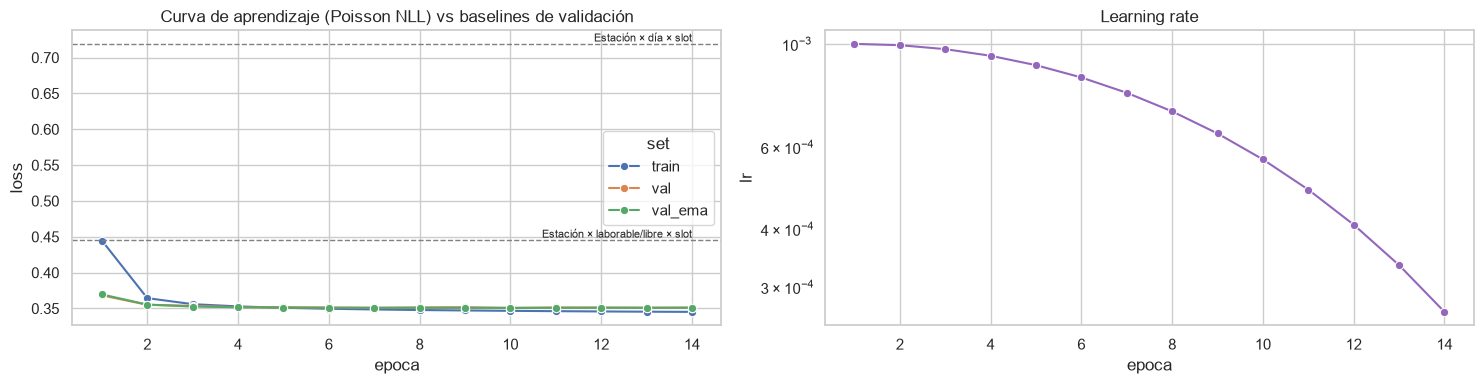

In [11]:
h = pd.DataFrame(historial)
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.lineplot(data=h.melt(id_vars='epoca', value_vars=['train', 'val', 'val_ema'], var_name='set', value_name='poisson'),
             x='epoca', y='poisson', hue='set', marker='o', ax=axes[0])
for _, r in DIAG.iloc[2:4].iterrows():
    axes[0].axhline(r['val_poisson_nll'], ls='--', lw=1, color='gray')
    axes[0].text(h['epoca'].max(), r['val_poisson_nll'], ' ' + r['referencia'], fontsize=8, va='bottom', ha='right')
axes[0].set(title='Curva de aprendizaje (Poisson NLL) vs baselines de validación', ylabel='loss')
sns.lineplot(data=h, x='epoca', y='lr', marker='o', ax=axes[1], color='tab:purple')
axes[1].set(title='Learning rate', yscale='log')
plt.tight_layout(); plt.show()

## 8. Evaluación en test vs baselines
- **Baseline A:** promedio de cada estación en train (ignora la hora).
- **Baseline B:** promedio por estación × día de semana × slot en train. Es el "sentido común" de un operador. **Si el modelo no le gana, no aporta valor.**

Métricas: **MAE** (error medio en bicis), **RMSE** y **devianza de Poisson** (la métrica natural para conteos; menor es mejor).

In [12]:
@torch.no_grad()
def predecir_tasas(idx):
    modelo.eval(); partes = []
    for b in iterar_batches(idx, CFG['batch_eval'], False):
        out, _ = adelante(b)
        partes.append(torch.exp(out).cpu())
    return torch.cat(partes).numpy()

def devianza_poisson(y, p):
    p = np.clip(p, 1e-8, None)
    with np.errstate(divide='ignore', invalid='ignore'):
        t = np.where(y > 0, y * np.log(y / p), 0.0)
    return float(np.mean(2 * (t - (y - p))))

def metricas(y, p, nombre):
    filas = []
    cols = TARGETS + ['salidas_total', 'llegadas_total']
    y_ext = np.column_stack([y, y[:, 0] + y[:, 1], y[:, 2] + y[:, 3]])
    p_ext = np.column_stack([p, p[:, 0] + p[:, 1], p[:, 2] + p[:, 3]])
    for k, c in enumerate(cols):
        e = p_ext[:, k] - y_ext[:, k]
        filas.append(dict(modelo=nombre, objetivo=c, MAE=np.abs(e).mean(), RMSE=np.sqrt((e ** 2).mean()),
                          devianza=devianza_poisson(y_ext[:, k], p_ext[:, k])))
    return filas

idx_test_np = IDX['test'].cpu().numpy()
idx_train_np = IDX['train'].cpu().numpy()
y_test = demanda[TARGETS].values[idx_test_np].astype(np.float64)
p_red = predecir_tasas(IDX['test'])

# Baselines calculados sólo con train
st_np, sl_np = demanda['station_idx'].values, demanda['slot_idx'].values
Y_np = demanda[TARGETS].values.astype(np.float64)
dow_np, sd_np = slots_f['dia_semana'].values, slots_f['slot_dia'].values

sumA = np.zeros((N_EST, 4)); cntA = np.zeros(N_EST)
np.add.at(sumA, st_np[idx_train_np], Y_np[idx_train_np]); np.add.at(cntA, st_np[idx_train_np], 1)
mediaA = sumA / np.maximum(cntA, 1)[:, None]
p_A = mediaA[st_np[idx_test_np]]

clave = lambda i: (st_np[i] * 7 + dow_np[sl_np[i]]) * 96 + sd_np[sl_np[i]]
sumB = np.zeros((N_EST * 7 * 96, 4)); cntB = np.zeros(N_EST * 7 * 96)
np.add.at(sumB, clave(idx_train_np), Y_np[idx_train_np]); np.add.at(cntB, clave(idx_train_np), 1)
kt = clave(idx_test_np)
p_B = np.where(cntB[kt][:, None] > 0, sumB[kt] / np.maximum(cntB[kt], 1)[:, None], p_A)

res = pd.DataFrame(metricas(y_test, p_A, 'Baseline A: media estación') +
                   metricas(y_test, p_B, 'Baseline B: media estación×día×slot') +
                   metricas(y_test, p_red, 'Red neuronal'))
tabla = res.pivot_table(index='objetivo', columns='modelo', values=['MAE', 'RMSE', 'devianza']).round(4)
display(tabla)

tot = res[res.objetivo.isin(['salidas_total', 'llegadas_total'])].groupby('modelo')[['MAE', 'RMSE', 'devianza']].mean()
mejora = (1 - tot.loc['Red neuronal'] / tot.loc['Baseline B: media estación×día×slot']) * 100
print('Mejora de la red vs Baseline B (totales):  ' + ' | '.join(f'{k}: {v:+.1f}%' for k, v in mejora.items()))

MAE                                                                        RMSE                                                                    devianza  \
modelo            Baseline A: media estación Baseline B: media estación×día×slot Red neuronal Baseline A: media estación Baseline B: media estación×día×slot Red neuronal Baseline A: media estación   
objetivo                                                                                                                                                                                               
llegadas_classic                      0.2644                              0.2251       0.2032                     0.5621                              0.5263       0.4857                     0.5958   
llegadas_electric                     0.5955                              0.4754       0.4237                     1.1169                              0.9389       0.8594                     1.1838   
llegadas_total                        0.7623                              0.5909       0.5203                     1.4424                              1.1713       1.0571                     1.4454   
salidas_classic                       0.2649                              0.2240       0.2030                     0.5824                              0.5401       0.4998                     0.5913   
salidas_electric                      0.5905                              0.4759       0.4245                     1.1224                              0.9516       0.8714                     1.1469   
salidas_total                         0.7518                              0.5836       0.5145                     1.4317                              1.1650       1.0488                     1.3822   

                                                                    
modelo            Baseline B: media estación×día×slot Red neuronal  
objetivo                                                            
llegadas_classic                               1.0234       0.4305  
llegadas_electric                              1.5018       0.7415  
llegadas_total                                 1.6307       0.8403  
salidas_classic                                0.9921       0.4274  
salidas_electric                               1.4601       0.7405  
salidas_total                                  1.5662       0.8227

Mejora de la red vs Baseline B (totales):  MAE: +11.9% | RMSE: +9.9% | devianza: +48.0%


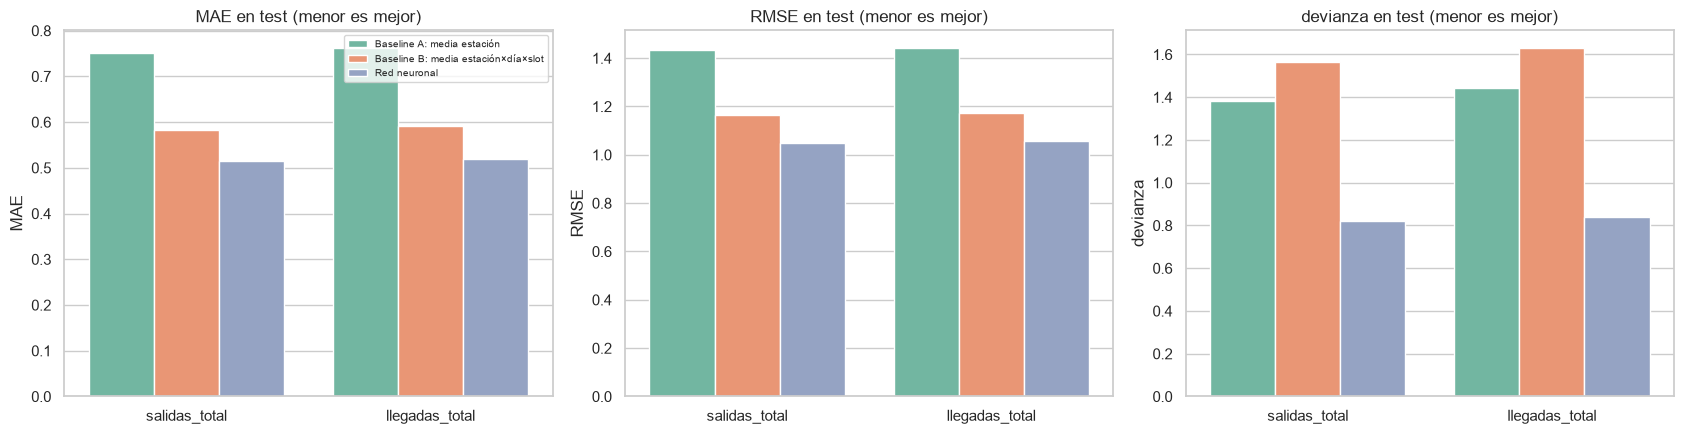

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
r_tot = res[res.objetivo.isin(['salidas_total', 'llegadas_total'])]
for ax, m in zip(axes, ['MAE', 'RMSE', 'devianza']):
    sns.barplot(data=r_tot, x='objetivo', y=m, hue='modelo', ax=ax, palette='Set2')
    ax.set(title=f'{m} en test (menor es mejor)', xlabel='')
    ax.legend(fontsize=7) if m == 'MAE' else ax.get_legend().remove()
plt.tight_layout(); plt.show()

### 8.1 Toda la ciudad: predicción vs realidad en el periodo de test

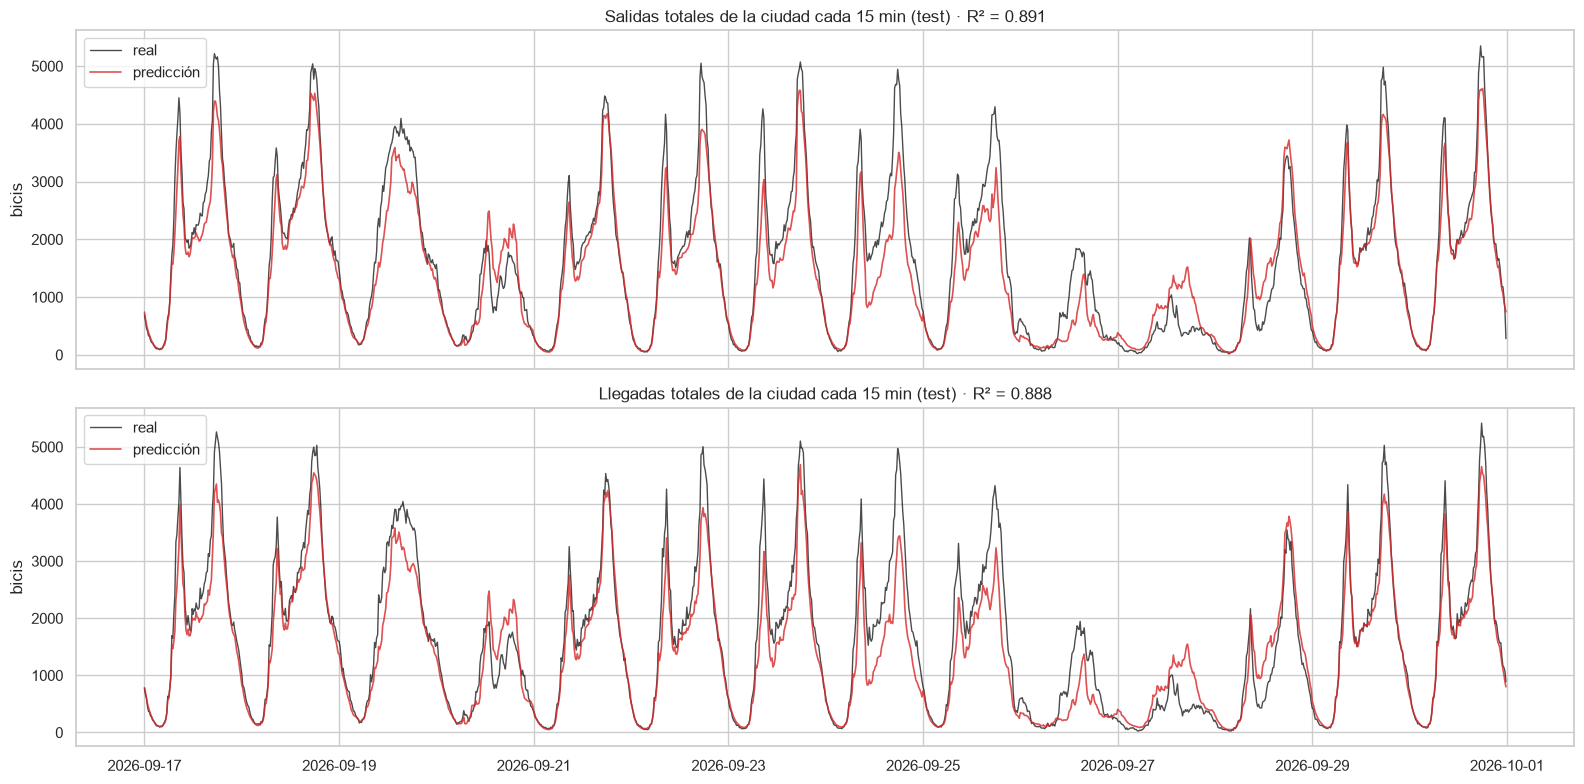

In [14]:
ts_test = slots_f['timestamp'].values[sl_np[idx_test_np]]
ciudad = (pd.DataFrame({'timestamp': ts_test,
                        'salidas_real': y_test[:, :2].sum(1), 'salidas_pred': p_red[:, :2].sum(1),
                        'llegadas_real': y_test[:, 2:].sum(1), 'llegadas_pred': p_red[:, 2:].sum(1)})
          .groupby('timestamp').sum())
fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
for ax, f in zip(axes, ['salidas', 'llegadas']):
    ax.plot(ciudad.index, ciudad[f'{f}_real'], label='real', lw=1, color='black', alpha=.7)
    ax.plot(ciudad.index, ciudad[f'{f}_pred'], label='predicción', lw=1.2, color='tab:red', alpha=.8)
    r2 = 1 - ((ciudad[f'{f}_real'] - ciudad[f'{f}_pred']) ** 2).sum() / ((ciudad[f'{f}_real'] - ciudad[f'{f}_real'].mean()) ** 2).sum()
    ax.set(title=f'{f.capitalize()} totales de la ciudad cada 15 min (test) · R² = {r2:.3f}', ylabel='bicis'); ax.legend()
plt.tight_layout(); plt.show()

### 8.2 Estaciones más activas: real vs predicción (agregado por hora para legibilidad)

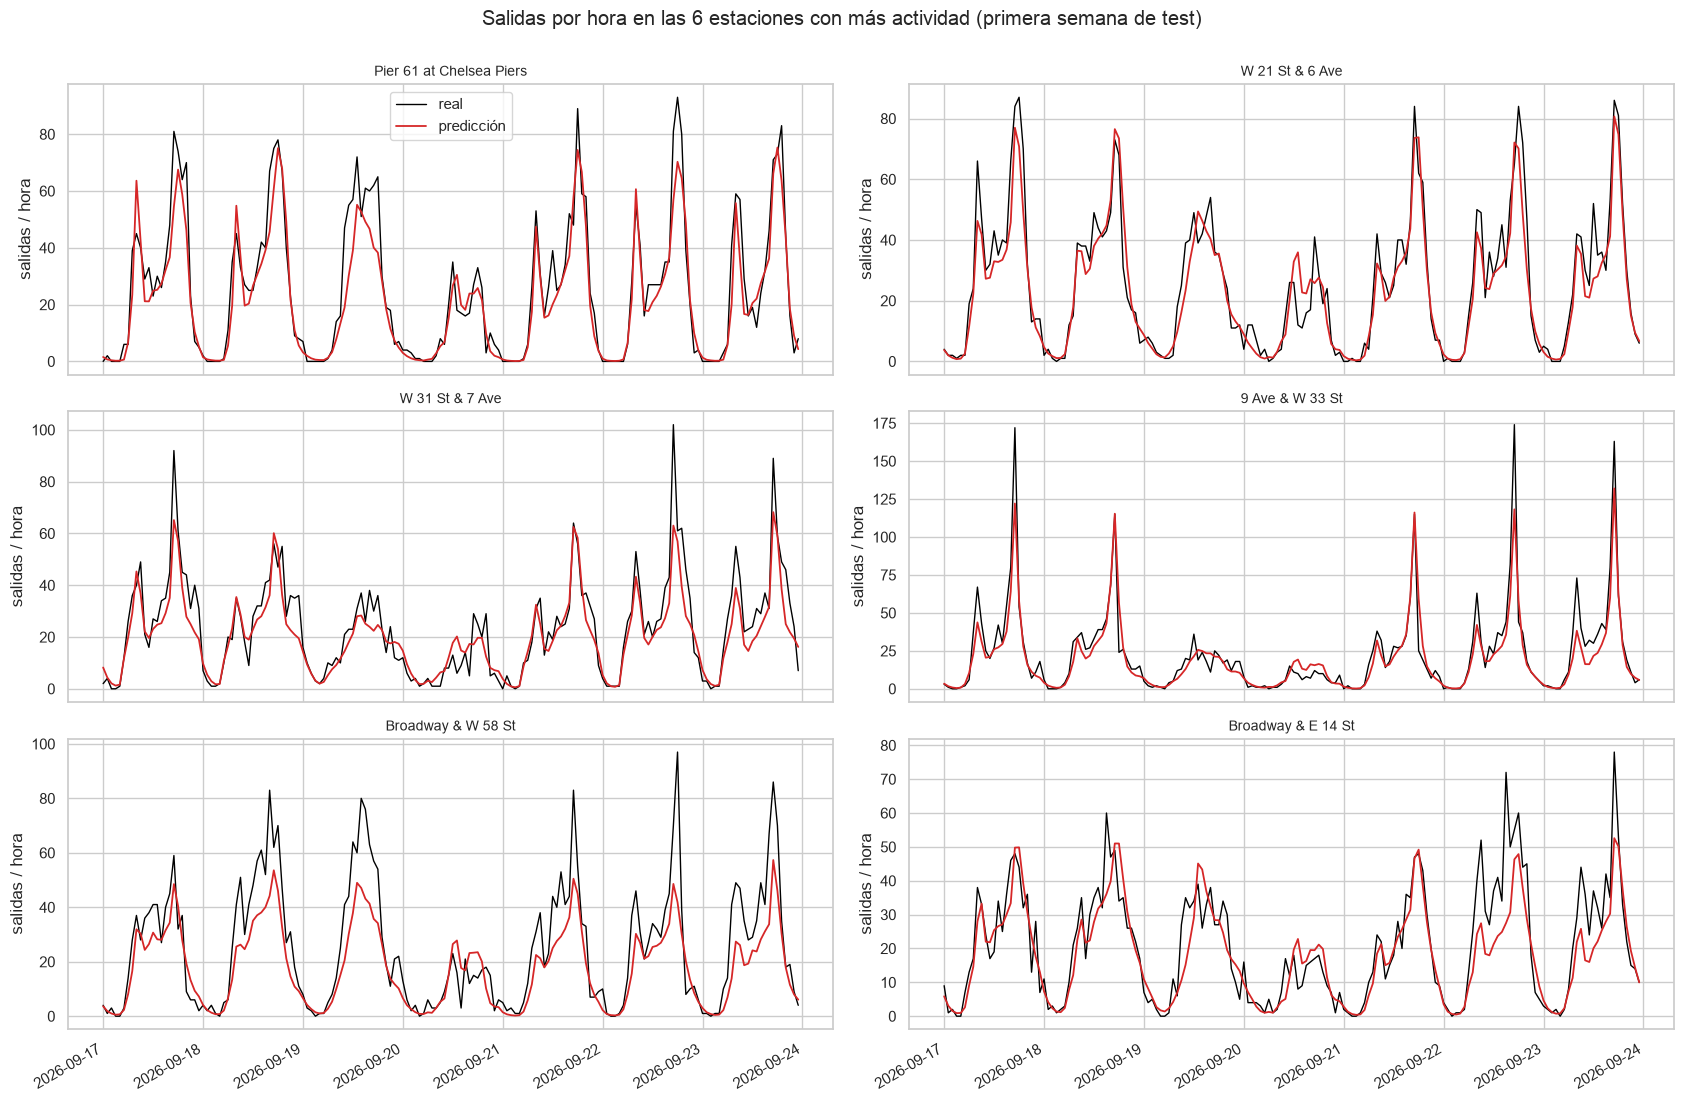

In [15]:
top_est = estaciones.nlargest(6, 'actividad_total')['station_idx'].values
df_t = pd.DataFrame({'station_idx': st_np[idx_test_np], 'timestamp': pd.to_datetime(ts_test),
                     'real': y_test[:, :2].sum(1), 'pred': p_red[:, :2].sum(1)})
df_t = df_t[df_t.station_idx.isin(top_est)]
df_t['hora'] = df_t['timestamp'].dt.floor('h')
df_t = df_t.groupby(['station_idx', 'hora'])[['real', 'pred']].sum().reset_index()
primeros = df_t['hora'].min() + pd.Timedelta(days=7)
df_t = df_t[df_t['hora'] < primeros]   # primera semana de test

fig, axes = plt.subplots(3, 2, figsize=(17, 11), sharex=True)
for ax, s in zip(axes.flat, top_est):
    d = df_t[df_t.station_idx == s]
    ax.plot(d['hora'], d['real'], color='black', lw=1, label='real')
    ax.plot(d['hora'], d['pred'], color='tab:red', lw=1.3, label='predicción')
    ax.set_title(estaciones.loc[s, 'name'][:45], fontsize=10); ax.set_ylabel('salidas / hora')
axes[0, 0].legend(); fig.autofmt_xdate()
fig.suptitle('Salidas por hora en las 6 estaciones con más actividad (primera semana de test)', y=1.0)
plt.tight_layout(); plt.show()

### 8.3 ¿Dónde y cuándo se equivoca más el modelo?

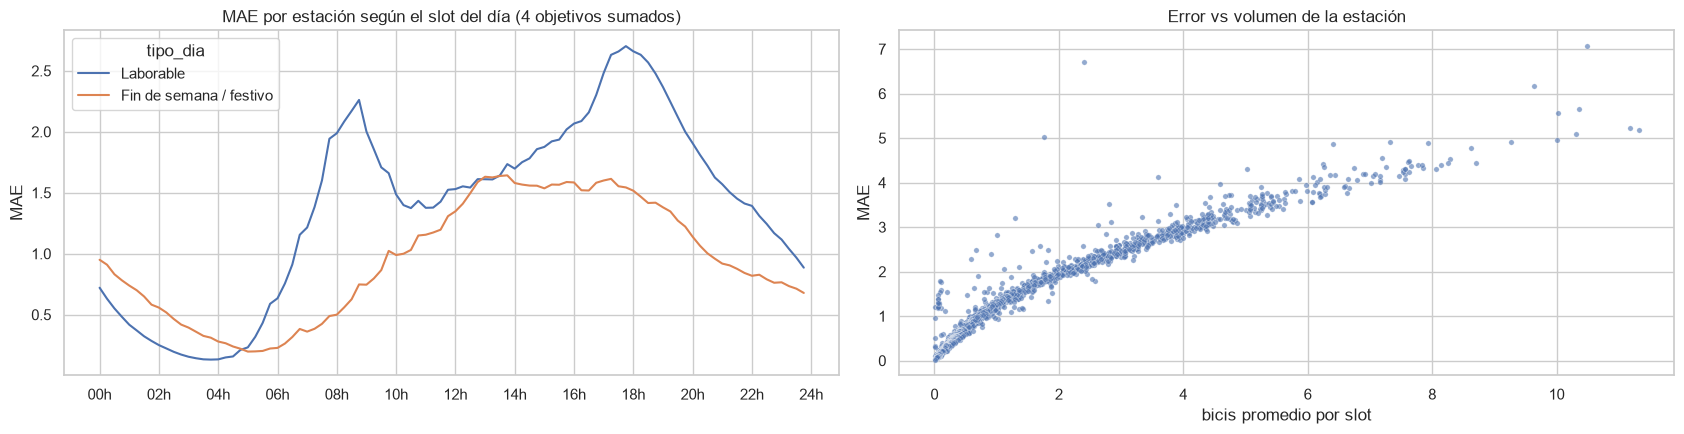

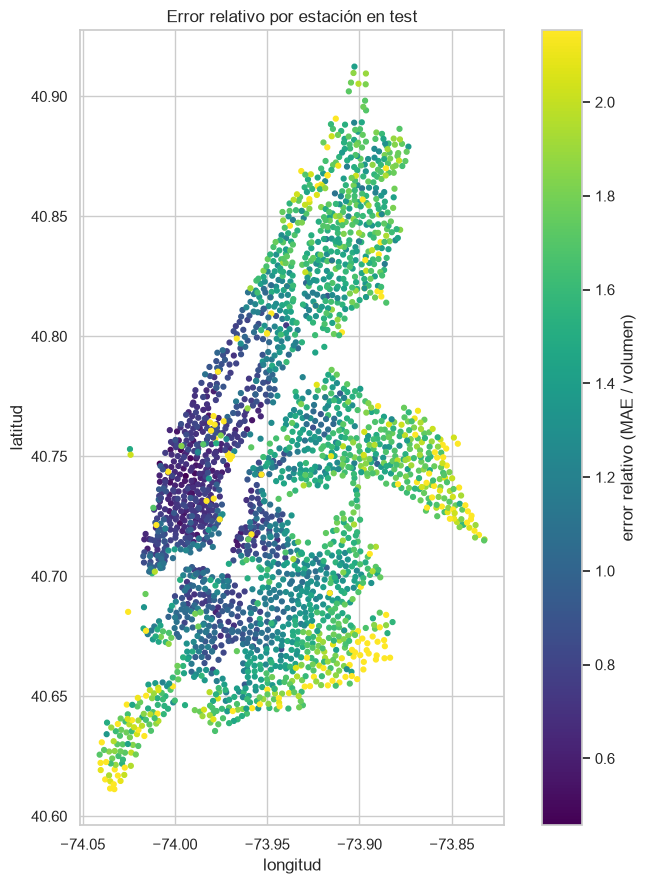

In [17]:
err = pd.DataFrame({'station_idx': st_np[idx_test_np], 'slot_dia': sd_np[sl_np[idx_test_np]],
                    'dia_libre': slots_f['dia_libre'].values[sl_np[idx_test_np]],
                    'abs_err': np.abs(p_red - y_test).sum(1), 'real': y_test.sum(1)})
fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
por_slot = err.groupby(['dia_libre', 'slot_dia'])[['abs_err', 'real']].mean().reset_index()
por_slot['tipo_dia'] = por_slot['dia_libre'].map({0: 'Laborable', 1: 'Fin de semana / festivo'})
sns.lineplot(data=por_slot, x='slot_dia', y='abs_err', hue='tipo_dia', ax=axes[0])
axes[0].set_xticks(range(0, 97, 8)); axes[0].set_xticklabels([f'{h:02d}h' for h in range(0, 25, 2)])
axes[0].set(title='MAE por estación según el slot del día (4 objetivos sumados)', xlabel='', ylabel='MAE')

por_est = err.groupby('station_idx')[['abs_err', 'real']].mean().join(estaciones.set_index('station_idx')[['lat', 'lng', 'name']])
sns.scatterplot(data=por_est, x='real', y='abs_err', ax=axes[1], s=15, alpha=.6)
axes[1].set(title='Error vs volumen de la estación', xlabel='bicis promedio por slot', ylabel='MAE')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 9))
sc = ax.scatter(por_est['lng'], por_est['lat'], c=por_est['abs_err'] / por_est['real'].clip(lower=1e-3),
                cmap='viridis', s=12, vmax=np.nanpercentile(por_est['abs_err'] / por_est['real'].clip(lower=1e-3), 95))
fig.colorbar(sc, ax=ax, label='error relativo (MAE / volumen)')
ax.set(title='Error relativo por estación en test', xlabel='longitud', ylabel='latitud'); ax.set_aspect(1.3)
plt.tight_layout(); plt.show()

### 8.4 ¿Qué aprendió el embedding de estaciones?
Se proyectan los embeddings a 2D con PCA. Las estaciones con patrones de uso parecidos (por ejemplo, zonas de oficinas que se llenan en la mañana frente a zonas residenciales que se vacían) deberían quedar cerca.

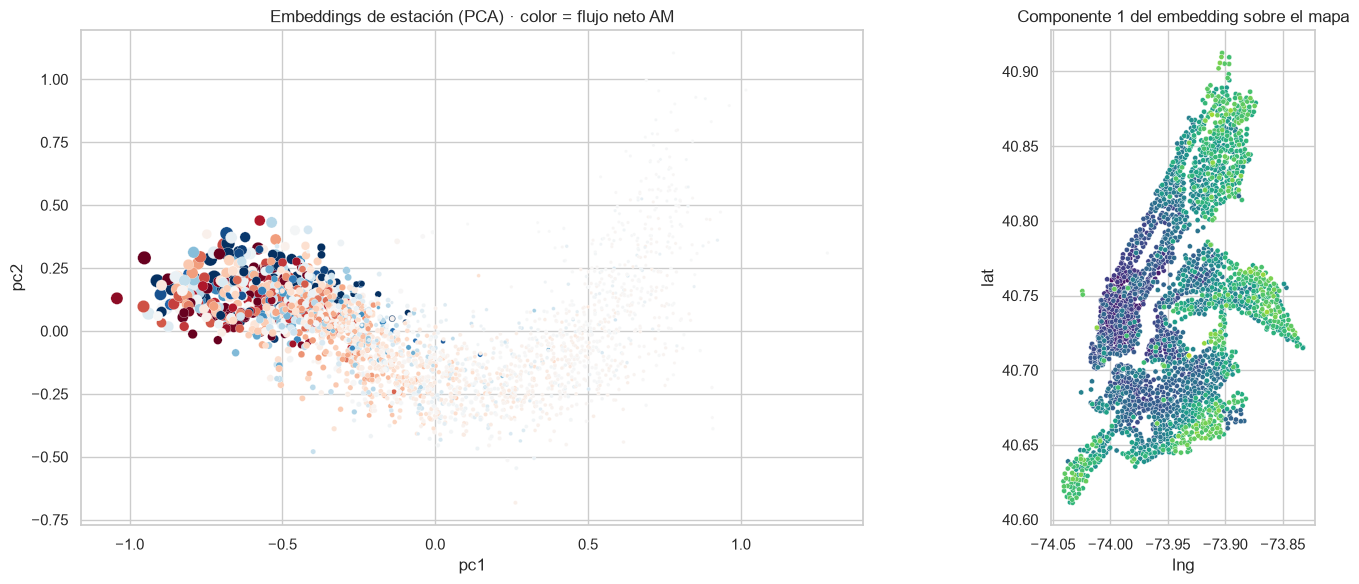

Varianza explicada por PC1+PC2: 72.3%


In [18]:
E = modelo.emb_est.weight.detach().float().cpu().numpy()
E = E - E.mean(0)
U, S, Vt = np.linalg.svd(E, full_matrices=False)
pc = E @ Vt[:2].T
est_pc = estaciones.assign(pc1=pc[:, 0], pc2=pc[:, 1])
lim = np.nanpercentile(np.abs(est_pc['neto_am']), 95)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(data=est_pc, x='pc1', y='pc2', hue='neto_am', palette='RdBu', hue_norm=(-lim, lim),
                size='actividad_total', sizes=(5, 120), ax=axes[0], legend=False)
axes[0].set(title='Embeddings de estación (PCA) · color = flujo neto AM')
sns.scatterplot(data=est_pc, x='lng', y='lat', hue='pc1', palette='viridis', s=14, ax=axes[1], legend=False)
axes[1].set(title='Componente 1 del embedding sobre el mapa'); axes[1].set_aspect(1.3)
plt.tight_layout(); plt.show()
print(f'Varianza explicada por PC1+PC2: {(S[:2] ** 2).sum() / (S ** 2).sum():.1%}')

## 9. Guardar el modelo

In [19]:
CHECKPOINT = MODEL_DIR / 'demanda_net_v2.pt'
torch.save({
    'state_dict': modelo.state_dict(),
    'cfg': CFG, 'n_est': N_EST, 'cont_cols': CONT_COLS, 'idx_clima': IDX_CLIMA, 'version': 2, 'escalar': ESCALAR, 'cat_cols': CAT_COLS,
    'mu': MU.to_dict(), 'sd': SD.to_dict(), 'targets': TARGETS, 'media_train': media_train,
    'estaciones': estaciones[['station_idx', 'station_id', 'name', 'lat', 'lng']].to_dict('list'),
    'meta': META, 'splits': {k: [str(pd.Timestamp(v.min()).date()), str(pd.Timestamp(v.max()).date())]
                             for k, v in [('train', fechas[:-(VAL_DIAS + TEST_DIAS)]), ('val', f_val), ('test', f_test)]},
    'metricas_test': res.to_dict('records'),
}, CHECKPOINT)
print(f'✅ Modelo guardado en {CHECKPOINT} ({CHECKPOINT.stat().st_size / 1e6:.1f} MB)')

✅ Modelo guardado en modelos/demanda_net_v2.pt (1.4 MB)


## 10. Predicción: dame una fecha y hora → salidas y llegadas para todas las estaciones
`predecir(fecha_hora)`:
1. Redondea hacia abajo al slot de 15 minutos.
2. Obtiene el clima: si la fecha está dentro de los datos históricos usa ese clima; si no, lo pide a Open-Meteo (pronóstico hasta 16 días adelante o archivo para el pasado). También puedes pasar el clima manualmente con `clima={...}`.
3. Devuelve un DataFrame con todas las estaciones: tasas esperadas por tipo, totales y flujo neto.

> Las salidas son **valores esperados** (por ejemplo, 2.4 bicis). Para inventario conviene usarlos tal cual o redondearlos con `redondear=True`.

In [20]:
LAT, LON, TZ = META['lat'], META['lon'], META['tz']
COLS_CLIMA_PRED = VARS_CLIMA + ['precip_prev2h']
CLIMA_HIST = slots_f.set_index('timestamp')[COLS_CLIMA_PRED]

def festivos_nyc(anios):
    try:
        import holidays
        return {pd.Timestamp(d) for d in holidays.US(state='NY', years=list(anios))}
    except ImportError:
        return {pd.Timestamp(d) for d in [
            '2025-01-01', '2025-01-20', '2025-02-17', '2025-05-26', '2025-06-19', '2025-07-04', '2025-09-01',
            '2025-10-13', '2025-11-11', '2025-11-27', '2025-12-25', '2026-01-01', '2026-01-19', '2026-02-16',
            '2026-05-25', '2026-06-19', '2026-07-03', '2026-07-04', '2026-09-07', '2026-10-12', '2026-11-11',
            '2026-11-26', '2026-12-25', '2027-01-01', '2027-01-18', '2027-02-15', '2027-05-31', '2027-06-18',
            '2027-07-05', '2027-09-06', '2027-10-11', '2027-11-11', '2027-11-25', '2027-12-24']}

def clima_open_meteo(inicio, fin):
    # Clima a 15 min entre dos timestamps (Open-Meteo: forecast si es reciente/futuro, archive si es pasado)
    hoy = pd.Timestamp.now(tz=TZ).tz_localize(None).normalize()
    url = ('https://api.open-meteo.com/v1/forecast' if inicio >= hoy - pd.Timedelta(days=60)
           else 'https://archive-api.open-meteo.com/v1/archive')
    desde = inicio.floor('D') - pd.Timedelta(days=1)      # un día antes para la lluvia de las 2 h previas
    params = dict(latitude=LAT, longitude=LON, start_date=f'{desde:%Y-%m-%d}',
                  end_date=f'{(fin + pd.Timedelta(days=1)):%Y-%m-%d}', hourly=','.join(VARS_CLIMA),
                  timezone=TZ, wind_speed_unit='kmh')
    r = requests.get(url, params=params, timeout=30); r.raise_for_status()
    h = pd.DataFrame(r.json()['hourly']); h['time'] = pd.to_datetime(h['time']); h = h.set_index('time')
    acum = ['precipitation', 'rain', 'snowfall']
    h[acum] = h[acum].shift(-1)                       # misma convención que el notebook 01
    idx15 = pd.date_range(desde, fin.floor('D') + pd.Timedelta(hours=23, minutes=45), freq='15min')
    h = h.reindex(h.index.union(idx15))
    cont = ['temperature_2m', 'apparent_temperature', 'relative_humidity_2m', 'cloud_cover', 'wind_speed_10m']
    h[cont] = h[cont].interpolate(method='time', limit_direction='both')
    h[acum + ['weather_code']] = h[acum + ['weather_code']].ffill().bfill()
    return agregar_lluvia_previa(h.reindex(idx15)[VARS_CLIMA])[COLS_CLIMA_PRED]

def construir_slots(timestamps, clima=None):
    ts = pd.DatetimeIndex(pd.to_datetime(timestamps)).floor('15min')
    s = pd.DataFrame({'timestamp': ts})
    fest = festivos_nyc(range(ts.min().year, ts.max().year + 1))
    s['es_festivo'] = ts.normalize().isin(list(fest)).astype(np.int8)
    if clima is not None:                             # clima manual: dict con las variables que quieras fijar
        base = CLIMA_HIST.median()
        for c in VARS_CLIMA:
            s[c] = clima.get(c, base[c])
        if 'precipitation' in clima and 'rain' not in clima:
            s['rain'] = clima['precipitation']
        # si no se indica, se asume que la lluvia actual también cayó en las 2 h previas
        s['precip_prev2h'] = clima.get('precip_prev2h', 2 * s['precipitation'])
    elif ts.isin(CLIMA_HIST.index).all():
        s[COLS_CLIMA_PRED] = CLIMA_HIST.loc[ts].values
    else:
        w = clima_open_meteo(ts.min(), ts.max())
        s[COLS_CLIMA_PRED] = w.loc[ts].values
    return preparar_features(s)

@torch.no_grad()
def predecir_slots(s_f):
    # Devuelve un arreglo [n_slots, n_est, 4] con las tasas esperadas
    xc, sd, dw, wc, lb = [t.to(DEVICE) for t in matriz_features(s_f)]
    n_s = len(s_f)
    est = torch.arange(N_EST, device=DEVICE).repeat(n_s)
    rep = lambda t: t.repeat_interleave(N_EST, dim=0)
    modelo.eval()
    with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USAR_AMP):
        out = modelo(est, rep(sd), rep(dw), rep(wc), rep(xc), rep(lb))
    return torch.exp(out.float()).cpu().numpy().reshape(n_s, N_EST, 4)

def predecir(fecha_hora, clima=None, redondear=False):
    s_f = construir_slots([fecha_hora], clima)
    p = predecir_slots(s_f)[0]
    r = estaciones[['station_id', 'name', 'lat', 'lng']].copy()
    r[TARGETS] = p
    r['salidas_total'] = p[:, 0] + p[:, 1]
    r['llegadas_total'] = p[:, 2] + p[:, 3]
    r['neto'] = r['llegadas_total'] - r['salidas_total']
    if redondear:
        num = TARGETS + ['salidas_total', 'llegadas_total', 'neto']
        r[num] = r[num].round().astype(int)
    r.attrs['slot'] = s_f['timestamp'].iloc[0]
    r.attrs['clima'] = s_f[VARS_CLIMA].iloc[0].to_dict()
    return r.sort_values('salidas_total', ascending=False).reset_index(drop=True)

def predecir_dia(fecha, clima=None):
    ts = pd.date_range(pd.Timestamp(fecha).normalize(), periods=96, freq='15min')
    s_f = construir_slots(ts, clima)
    p = predecir_slots(s_f)
    filas = pd.DataFrame({'timestamp': np.repeat(ts, N_EST), 'station_idx': np.tile(np.arange(N_EST), 96)})
    filas[TARGETS] = p.reshape(-1, 4)
    filas['salidas_total'] = filas[TARGETS[:2]].sum(axis=1)
    filas['llegadas_total'] = filas[TARGETS[2:]].sum(axis=1)
    filas['neto'] = filas['llegadas_total'] - filas['salidas_total']
    return filas.merge(estaciones[['station_idx', 'station_id', 'name']], on='station_idx')

### 10.1 Ejemplo: un slot del periodo de test, comparado con lo que realmente pasó

In [21]:
ejemplo = pd.Timestamp(f_test[2]) + pd.Timedelta(hours=8, minutes=37)    # 08:37 → slot 08:30
pred = predecir(ejemplo)
print(f"Slot: {pred.attrs['slot']} | clima: {pred.attrs['clima']['temperature_2m']:.1f}°C, "
      f"lluvia {pred.attrs['clima']['precipitation']:.1f} mm/h")

slot_i = int(slots_f.index[slots_f['timestamp'] == pred.attrs['slot']][0])
reales = demanda[demanda.slot_idx == slot_i].merge(estaciones[['station_idx', 'station_id']], on='station_idx')
comp = pred.merge(reales[['station_id', 'salidas_classic', 'salidas_electric', 'llegadas_classic', 'llegadas_electric']]
                  .rename(columns=lambda c: c if c == 'station_id' else c + '_real'), on='station_id', how='left')
display(comp[['name', 'salidas_classic', 'salidas_classic_real', 'salidas_electric', 'salidas_electric_real',
              'llegadas_total', 'neto']].head(15).round(2))
print(f"Ciudad → salidas predichas: {pred.salidas_total.sum():.0f} | reales: "
      f"{(comp.salidas_classic_real + comp.salidas_electric_real).sum():.0f}")

Slot: 2026-09-19 08:30:00 | clima: 16.9°C, lluvia 0.0 mm/h


,name,salidas_classic,salidas_classic_real,salidas_electric,salidas_electric_real,llegadas_total,neto
0,11 Ave & W 41 St,1.42,1.0,2.46,2.0,1.94,-1.93
1,Central Park S & 6 Ave,1.03,7.0,1.97,4.0,3.55,0.55
2,W 43 St & 10 Ave,1.01,0.0,1.89,0.0,1.22,-1.69
3,7 Ave & Central Park South,0.89,0.0,1.99,0.0,2.38,-0.50
4,W 21 St & 6 Ave,1.23,0.0,1.61,6.0,3.03,0.19
5,Broadway & W 58 St,0.96,2.0,1.86,0.0,2.93,0.12
6,Columbus Ave & W 72 St,0.85,0.0,1.92,3.0,2.16,-0.61
7,E 33 St & 1 Ave,0.58,2.0,2.14,2.0,1.81,-0.91
8,Franklin St & Dupont St,0.62,1.0,1.99,1.0,1.35,-1.27
9,E 31 St & 3 Ave,0.87,4.0,1.71,1.0,1.21,-1.37


Ciudad → salidas predichas: 1078 | reales: 1408


### 10.2 Mapa de dónde se concentrará la demanda en ese slot

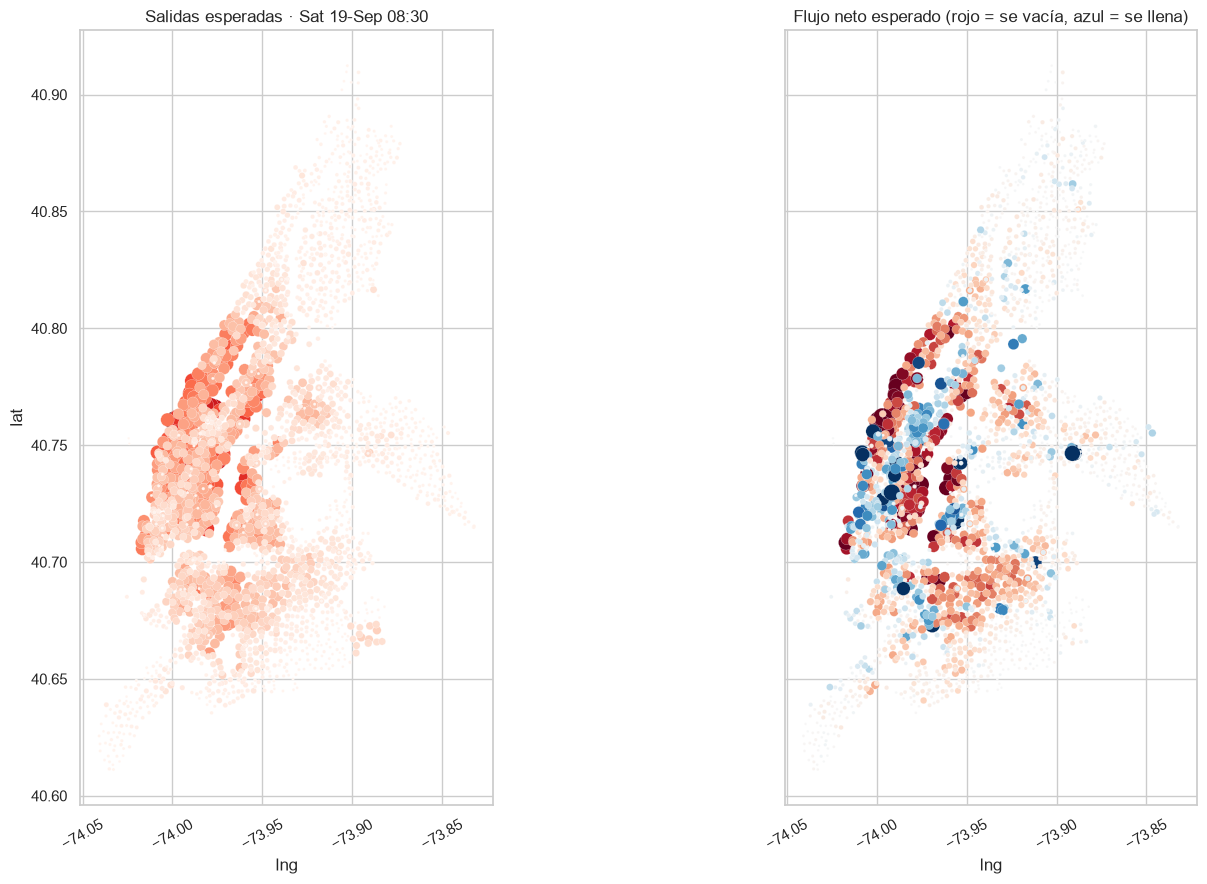

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 9), sharex=True, sharey=True)
sns.scatterplot(data=pred, x='lng', y='lat', size='salidas_total', hue='salidas_total', palette='Reds',
                sizes=(3, 200), ax=axes[0], legend=False)
axes[0].set(title=f"Salidas esperadas · {pred.attrs['slot']:%a %d-%b %H:%M}"); axes[0].set_aspect(1.3)
lim = np.percentile(np.abs(pred['neto']), 98) or 1
sns.scatterplot(data=pred, x='lng', y='lat', hue='neto', palette='RdBu', hue_norm=(-lim, lim),
                size=np.abs(pred['neto']), sizes=(3, 200), ax=axes[1], legend=False)
axes[1].set(title='Flujo neto esperado (rojo = se vacía, azul = se llena)'); axes[1].set_aspect(1.3)
for ax in axes: ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

### 10.3 Un día completo: perfil de las estaciones con más demanda

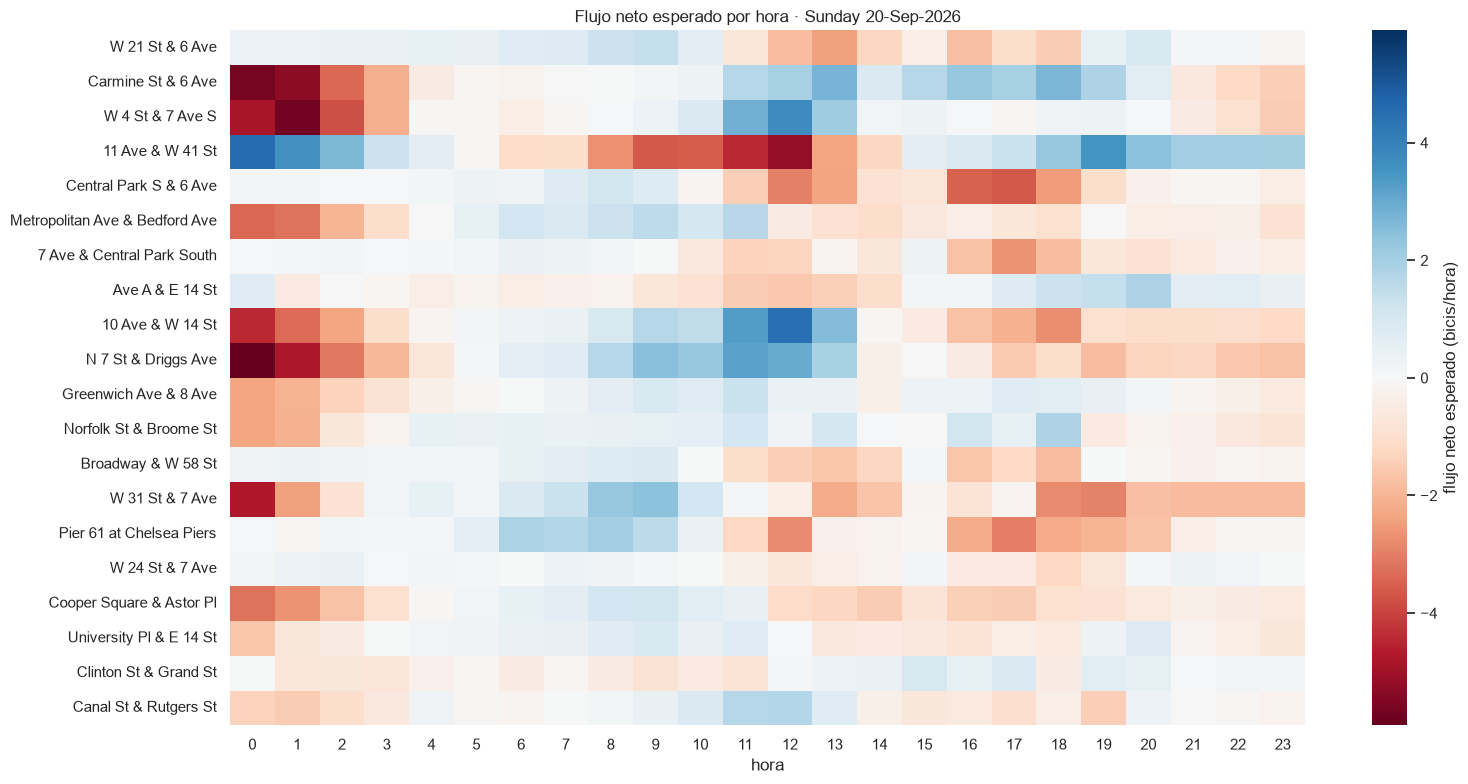

In [23]:
dia = predecir_dia(f_test[3])
top20 = dia.groupby('name')['salidas_total'].sum().nlargest(20).index
piv = (dia[dia.name.isin(top20)].assign(hora=lambda d: d.timestamp.dt.hour)
       .groupby(['name', 'hora'])['neto'].sum().unstack())
lim = np.abs(piv.values).max()
fig, ax = plt.subplots(figsize=(16, 8))
sns.heatmap(piv.loc[top20], cmap='RdBu', center=0, vmin=-lim, vmax=lim, ax=ax,
            cbar_kws={'label': 'flujo neto esperado (bicis/hora)'})
ax.set(title=f'Flujo neto esperado por hora · {pd.Timestamp(f_test[3]):%A %d-%b-%Y}', xlabel='hora', ylabel='')
plt.tight_layout(); plt.show()

### 10.4 Predicción a futuro (clima de pronóstico o manual)
Para fechas fuera del histórico se descarga el pronóstico de Open-Meteo (hasta ~16 días adelante). Si no hay internet, o si quieres simular escenarios, pasa el clima a mano.

In [25]:
manana_8am = (pd.Timestamp.now(tz=TZ).tz_localize(None).normalize() + pd.Timedelta(days=1, hours=8))
try:
    futuro = predecir(manana_8am)
    print(f"Pronóstico Open-Meteo para {futuro.attrs['slot']}: {futuro.attrs['clima']['temperature_2m']:.1f}°C")
except Exception as e:
    print('No se pudo descargar el pronóstico, uso clima manual →', type(e).__name__)
    futuro = predecir(manana_8am, clima={'temperature_2m': 20, 'apparent_temperature': 20, 'precipitation': 0})
display(futuro[['name', 'salidas_total', 'llegadas_total', 'neto']].head(10).round(2))

# Escenario: mismo momento con lluvia fuerte
lluvioso = predecir(manana_8am, clima={'temperature_2m': 18, 'apparent_temperature': 16, 'precipitation': 6,
                                       'weather_code': 63, 'cloud_cover': 100})
print(f'Salidas totales en la ciudad → normal: {futuro.salidas_total.sum():.0f} | '
      f'con lluvia fuerte: {lluvioso.salidas_total.sum():.0f}')

Pronóstico Open-Meteo para 2026-10-11 08:00:00: 13.6°C


,name,salidas_total,llegadas_total,neto
0,11 Ave & W 41 St,2.48,1.40,-1.09
1,E 33 St & 1 Ave,2.36,1.58,-0.78
2,W 43 St & 10 Ave,1.81,1.01,-0.80
3,1 Ave & E 68 St,1.77,1.66,-0.11
4,Henry St & Grand St,1.67,1.12,-0.55
5,1 Ave & E 18 St,1.66,0.77,-0.89
6,E 31 St & 3 Ave,1.63,0.94,-0.69
7,1 Ave & E 38 St,1.63,1.27,-0.36
8,W 31 St & 7 Ave,1.62,2.98,1.35
9,West End Ave & W 60 St,1.60,1.09,-0.52


Salidas totales en la ciudad → normal: 696 | con lluvia fuerte: 230


In [26]:
#INCLUYE ACA UN EXPORT A ONNX PARA PODER USAR EL MODELO EN OTROS ENTORNOS
# Exportar el modelo a ONNX

## 11. Siguientes pasos sugeridos
- **Más meses de datos:** basta con agregar las carpetas y re-ejecutar el notebook 01. Con un año completo, el modelo aprenderá estacionalidad (conviene añadir el mes o el día del año como feature).
- **Ajuste de hiperparámetros:** tamaño de los embeddings, capas, dropout y `lr` en `CFG`.
- **Sobre-dispersión:** si la varianza es mucho mayor que la media, probar una pérdida *Negative Binomial*.
- **Modo con lags** (más preciso a corto plazo): agregar la demanda de los slots previos como entrada para predicciones de la siguiente hora.

## 12. Exportar el modelo a ONNX
Se exporta un grafo que ya incluye **todo el preprocesamiento**: seno/coseno, fin de semana, día libre, logaritmos de lluvia, grupos de `weather_code`, estandarización con las medias de train y el cálculo para **todas las estaciones a la vez**. Quien use el `.onnx` (Python, C#, Java, JavaScript, una app móvil o un servidor) sólo necesita mandar el día, la hora y el clima.

**Entradas** (S = número de slots a predecir; puede variar en cada llamada):

| nombre | forma | tipo | contenido |
|---|---|---|---|
| `slot_dia` | [S] | int64 | 0–95 → hora·4 + minuto//15 (08:30 → 34) |
| `dia_semana` | [S] | int64 | 0 = lunes … 6 = domingo |
| `es_festivo` | [S] | float32 | 1 si es festivo, 0 si no |
| `clima` | [S, 6] | float32 | `temperature_2m` (°C), `relative_humidity_2m` (%), `wind_speed_10m` (km/h), `precipitation` (mm/h), `precip_prev2h` (mm en las 2 h previas), `weather_code` (WMO) |

**Salida:** `lambda` con forma [S, n_estaciones, 4] = bicis esperadas en ese slot de 15 minutos, en el orden `salidas_classic, salidas_electric, llegadas_classic, llegadas_electric`. El índice de estación corresponde a `estaciones_onnx.json`.

> Requisitos: `pip install onnx onnxscript onnxruntime`

In [27]:
import onnx
import onnxruntime as ort

COLS_CLIMA_ONNX = ['temperature_2m', 'relative_humidity_2m', 'wind_speed_10m',
                   'precipitation', 'precip_prev2h', 'weather_code']

class DemandaONNX(nn.Module):
    # Envuelve DemandaNet: entradas crudas por slot → λ para todas las estaciones
    def __init__(self, red, n_est, cont_cols, escalar, mu, sd):
        super().__init__()
        self.red = red
        self.n_est = n_est
        self.cont_cols = list(cont_cols)
        self.register_buffer('estaciones', torch.arange(n_est, dtype=torch.long))
        self.register_buffer('limites_wc', torch.tensor([1., 3., 48., 67., 77., 86.]))
        media = torch.zeros(len(cont_cols)); desv = torch.ones(len(cont_cols))
        for c in escalar:
            media[self.cont_cols.index(c)] = float(mu[c]); desv[self.cont_cols.index(c)] = float(sd[c])
        self.register_buffer('media', media)
        self.register_buffer('desv', desv)

    def forward(self, slot_dia, dia_semana, es_festivo, clima):
        sd_f = slot_dia.to(torch.float32); dw_f = dia_semana.to(torch.float32)
        temp, hum, viento = clima[:, 0], clima[:, 1], clima[:, 2]
        precip, prev2h, wcode = clima[:, 3].clamp(min=0), clima[:, 4].clamp(min=0), clima[:, 5]
        fin_semana = (dia_semana >= 5).to(torch.float32)
        dia_libre_f = torch.maximum(fin_semana, es_festivo)
        f = {
            'slot_sin': torch.sin(2 * math.pi * sd_f / 96), 'slot_cos': torch.cos(2 * math.pi * sd_f / 96),
            'dow_sin': torch.sin(2 * math.pi * dw_f / 7), 'dow_cos': torch.cos(2 * math.pi * dw_f / 7),
            'es_fin_semana': fin_semana, 'es_festivo': es_festivo, 'dia_libre': dia_libre_f,
            'temperature_2m': temp, 'relative_humidity_2m': hum, 'wind_speed_10m': viento,
            'precip_log': torch.log1p(precip), 'precip_prev_log': torch.log1p(prev2h),
            'llueve': (precip >= 0.1).to(torch.float32),
        }
        xc = (torch.stack([f[c] for c in self.cont_cols], dim=1) - self.media) / self.desv     # [S, n_cont]
        wc = (wcode.unsqueeze(1) > self.limites_wc).to(torch.long).sum(dim=1)                   # grupo 0..6
        libre = dia_libre_f.to(torch.long)

        S, N = slot_dia.shape[0], self.n_est
        est = self.estaciones.unsqueeze(0).expand(S, N).reshape(-1)
        rep = lambda t: t.unsqueeze(1).expand(S, N).reshape(-1)
        xc_r = xc.unsqueeze(1).expand(S, N, xc.shape[1]).reshape(-1, xc.shape[1])
        log_lambda = self.red(est, rep(slot_dia), rep(dia_semana), rep(wc), xc_r, rep(libre))
        return torch.exp(log_lambda).reshape(S, N, 4)

red_cpu = copy.deepcopy(modelo).float().cpu().eval()
red_cpu.cfg = dict(red_cpu.cfg, ruido_clima=0.0)          # por seguridad: sin ruido fuera de train
envoltura = DemandaONNX(red_cpu, N_EST, CONT_COLS, ESCALAR, MU, SD).eval()

# Comprobación: la envoltura debe dar lo mismo que predecir_slots() del notebook
muestra = slots_f[slots_f.split == 'test'].sample(8, random_state=0).sort_values('timestamp')
def entradas_desde_slots(s_f):
    return (torch.tensor(s_f['slot_dia'].values, dtype=torch.long),
            torch.tensor(s_f['dia_semana'].values, dtype=torch.long),
            torch.tensor(s_f['es_festivo'].values, dtype=torch.float32),
            torch.tensor(s_f[COLS_CLIMA_ONNX].values, dtype=torch.float32))
ejemplo_in = entradas_desde_slots(muestra)
with torch.no_grad():
    p_envoltura = envoltura(*ejemplo_in).numpy()
p_notebook = predecir_slots(muestra)
dif = np.abs(p_envoltura - p_notebook).max()
print(f'Forma de salida: {p_envoltura.shape} | diferencia máxima vs predecir_slots: {dif:.2e}')
assert dif < 1e-3, 'La envoltura no reproduce el preprocesamiento del notebook'

Forma de salida: (8, 2461, 4) | diferencia máxima vs predecir_slots: 1.91e-06


In [28]:
ONNX_PATH = MODEL_DIR / 'demanda_net_v2.onnx'
NOMBRES_IN = ['slot_dia', 'dia_semana', 'es_festivo', 'clima']

def exportar_dynamo():
    S = torch.export.Dim('S', min=1, max=100_000)
    prog = torch.onnx.export(envoltura, ejemplo_in, dynamo=True, input_names=NOMBRES_IN, output_names=['lambda'],
                             dynamic_shapes={'slot_dia': {0: S}, 'dia_semana': {0: S}, 'es_festivo': {0: S}, 'clima': {0: S}})
    prog.save(str(ONNX_PATH), external_data=False)

def exportar_clasico():
    torch.onnx.export(envoltura, ejemplo_in, str(ONNX_PATH), dynamo=False, opset_version=17,
                      input_names=NOMBRES_IN, output_names=['lambda'],
                      dynamic_axes={n: {0: 'S'} for n in NOMBRES_IN} | {'lambda': {0: 'S'}})

try:
    exportar_dynamo(); metodo = 'torch.export (dynamo)'
except Exception as e:
    print('Exportador dynamo falló, uso el exportador clásico →', type(e).__name__, str(e)[:200])
    exportar_clasico(); metodo = 'TorchScript (clásico)'

modelo_onnx = onnx.load(str(ONNX_PATH))
onnx.checker.check_model(modelo_onnx)
modelo_onnx.doc_string = ('Citi Bike: bicis esperadas por estación cada 15 min. Salida [S, n_estaciones, 4] = '
                          'salidas_classic, salidas_electric, llegadas_classic, llegadas_electric')
for k, v in {'n_estaciones': N_EST, 'targets': ','.join(TARGETS), 'clima_cols': ','.join(COLS_CLIMA_ONNX),
             'slot_minutos': '15', 'version': 'v2'}.items():
    modelo_onnx.metadata_props.append(onnx.StringStringEntryProto(key=k, value=str(v)))
onnx.save(modelo_onnx, str(ONNX_PATH))

print(f'✅ Exportado con {metodo}: {ONNX_PATH} ({ONNX_PATH.stat().st_size / 1e6:.1f} MB)')
for i in modelo_onnx.graph.input:
    dims = [d.dim_param or d.dim_value for d in i.type.tensor_type.shape.dim]
    print(f'   entrada {i.name:<11} {dims}')
for o in modelo_onnx.graph.output:
    dims = [d.dim_param or d.dim_value for d in o.type.tensor_type.shape.dim]
    print(f'   salida  {o.name:<11} {dims}')

W1009 22:20:03.293000 91727 torch/onnx/_internal/exporter/_registration.py:107] torchvision is not installed. Skipping torchvision::nms
W1009 22:20:03.294000 91727 torch/onnx/_internal/exporter/_registration.py:107] torchvision is not installed. Skipping torchvision::roi_align
W1009 22:20:03.295000 91727 torch/onnx/_internal/exporter/_registration.py:107] torchvision is not installed. Skipping torchvision::roi_pool
W1009 22:20:03.295000 91727 torch/onnx/_internal/exporter/_registration.py:107] torchvision is not installed. Skipping torchvision::deform_conv2d


[torch.onnx] Obtain model graph for `DemandaONNX([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `DemandaONNX([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
✅ Exportado con torch.export (dynamo): modelos/demanda_net_v2.onnx (1.4 MB)
   entrada slot_dia    ['S']
   entrada dia_semana  ['S']
   entrada es_festivo  ['S']
   entrada clima       ['S', 6]
   salida  lambda      ['S', 2461, 4]


/Users/eduardoporto/Desktop/datarush_ml/venv/lib/python3.14/site-packages/torch/onnx/_internal/exporter/_onnx_program.py:486: UserWarning: # The axis name: S will not be used, since it shares the same shape constraints with another axis: S.
  rename_mapping = _dynamic_shapes.create_rename_mapping(


### 12.1 Verificación con ONNX Runtime
Se compara ONNX Runtime contra PyTorch: en la muestra, con un tamaño de lote distinto (para confirmar que el eje dinámico funciona) y sobre **todo el periodo de test**, recalculando las métricas.

In [29]:
sesion = ort.InferenceSession(str(ONNX_PATH), providers=['CPUExecutionProvider'])
def a_numpy(entradas):
    return {n: t.numpy() for n, t in zip(NOMBRES_IN, entradas)}

p_ort = sesion.run(['lambda'], a_numpy(ejemplo_in))[0]
print(f'Muestra (S=8)  → diferencia máxima ONNX vs PyTorch: {np.abs(p_ort - p_envoltura).max():.2e}')

test_slots = slots_f[slots_f.split == 'test']
t0 = time.time()
p_ort_test = np.concatenate([sesion.run(['lambda'], a_numpy(entradas_desde_slots(test_slots.iloc[i:i + 96])))[0]
                             for i in range(0, len(test_slots), 96)])
seg = time.time() - t0
print(f'Test completo  → {len(test_slots):,} slots × {N_EST:,} estaciones en {seg:.1f}s '
      f'({seg / len(test_slots) * 1000:.1f} ms por slot, todas las estaciones)')

# Métricas recalculadas con las predicciones de ONNX sobre las filas reales de test
pos_slot = {s: k for k, s in enumerate(test_slots['slot_idx'].values)}
fila_slot = np.array([pos_slot[s] for s in sl_np[idx_test_np]])
p_onnx_filas = p_ort_test[fila_slot, st_np[idx_test_np]]
print(f'Diferencia máxima vs predicciones PyTorch de test: {np.abs(p_onnx_filas - p_red).max():.2e}')
comp_onnx = pd.DataFrame(metricas(y_test, p_red, 'PyTorch') + metricas(y_test, p_onnx_filas, 'ONNX'))
display(comp_onnx.pivot_table(index='objetivo', columns='modelo', values=['MAE', 'devianza']).round(5))

Muestra (S=8)  → diferencia máxima ONNX vs PyTorch: 1.43e-06
Test completo  → 1,344 slots × 2,461 estaciones en 3.0s (2.3 ms por slot, todas las estaciones)
Diferencia máxima vs predicciones PyTorch de test: 1.53e-05


MAE          devianza         
modelo                ONNX  PyTorch     ONNX  PyTorch
objetivo                                             
llegadas_classic   0.20320  0.20320  0.43047  0.43047
llegadas_electric  0.42369  0.42369  0.74146  0.74146
llegadas_total     0.52026  0.52026  0.84028  0.84028
salidas_classic    0.20301  0.20301  0.42741  0.42741
salidas_electric   0.42450  0.42450  0.74046  0.74046
salidas_total      0.51446  0.51446  0.82272  0.82272

### 12.2 Archivos para producción
Además del `.onnx` se guarda `estaciones_onnx.json`, con el catálogo de estaciones (el índice coincide con el eje 1 de la salida) y la información necesaria para construir las entradas.

In [30]:
info = {
    'modelo': ONNX_PATH.name, 'version': 'v2', 'slot_minutos': 15,
    'entradas': {'slot_dia': 'int64 [S], hora*4 + minuto//15 (0..95)',
                 'dia_semana': 'int64 [S], 0=lunes ... 6=domingo',
                 'es_festivo': 'float32 [S], 1 festivo / 0 normal (EE. UU. + estado de NY)',
                 'clima': f'float32 [S, 6]: {COLS_CLIMA_ONNX}'},
    'salida': {'lambda': f'float32 [S, {N_EST}, 4]: {TARGETS}'},
    'notas_clima': ('Open-Meteo, NYC (40.7128, -74.0060), zona America/New_York. precipitation = mm/h de la hora en curso; '
                    'precip_prev2h = mm acumulados en las 2 h anteriores al slot.'),
    'periodo_entrenamiento': {k: v for k, v in zip(['train', 'val', 'test'],
                              [[str(pd.Timestamp(fechas[0]).date()), str(pd.Timestamp(fechas[-(VAL_DIAS + TEST_DIAS) - 1]).date())],
                               [str(pd.Timestamp(f_val[0]).date()), str(pd.Timestamp(f_val[-1]).date())],
                               [str(pd.Timestamp(f_test[0]).date()), str(pd.Timestamp(f_test[-1]).date())]])},
    'estaciones': estaciones[['station_idx', 'station_id', 'name', 'lat', 'lng']].to_dict('records'),
}
INFO_PATH = MODEL_DIR / 'estaciones_onnx.json'
INFO_PATH.write_text(json.dumps(info, ensure_ascii=False, indent=1, default=float))
print(f'✅ {INFO_PATH} ({INFO_PATH.stat().st_size / 1e3:.0f} KB)')

✅ modelos/estaciones_onnx.json (347 KB)


### 12.3 Ejemplo de uso **sin PyTorch** (sólo `onnxruntime` + `numpy`)
Esta celda simula cómo se usaría el modelo en otro proyecto o servidor: no utiliza nada del notebook salvo las rutas de los archivos.

In [31]:
import json as _json
import numpy as _np
import onnxruntime as _ort

def cargar_predictor(ruta_onnx, ruta_info):
    sesion = _ort.InferenceSession(str(ruta_onnx), providers=['CPUExecutionProvider'])
    info = _json.loads(open(ruta_info, encoding='utf-8').read())
    return sesion, info

def predecir_onnx(sesion, info, hora, minuto, dia_semana, clima, es_festivo=False):
    # clima: dict con temperature_2m, relative_humidity_2m, wind_speed_10m, precipitation, precip_prev2h, weather_code
    entradas = {
        'slot_dia':   _np.array([hora * 4 + minuto // 15], dtype=_np.int64),
        'dia_semana': _np.array([dia_semana], dtype=_np.int64),
        'es_festivo': _np.array([1.0 if es_festivo else 0.0], dtype=_np.float32),
        'clima':      _np.array([[clima['temperature_2m'], clima['relative_humidity_2m'], clima['wind_speed_10m'],
                                  clima['precipitation'], clima['precip_prev2h'], clima['weather_code']]], dtype=_np.float32),
    }
    lam = sesion.run(['lambda'], entradas)[0][0]          # [n_estaciones, 4]
    filas = []
    for est, v in zip(info['estaciones'], lam):
        filas.append({'station_id': est['station_id'], 'name': est['name'],
                      'salidas': float(v[0] + v[1]), 'llegadas': float(v[2] + v[3]),
                      'neto': float(v[2] + v[3] - v[0] - v[1])})
    return sorted(filas, key=lambda f: -f['salidas'])

ses, inf = cargar_predictor(ONNX_PATH, INFO_PATH)
r = predecir_onnx(ses, inf, hora=8, minuto=37, dia_semana=1,      # martes 08:37 → slot 08:30
                  clima={'temperature_2m': 21, 'relative_humidity_2m': 60, 'wind_speed_10m': 10,
                         'precipitation': 0, 'precip_prev2h': 0, 'weather_code': 1})
print('Martes 08:30, despejado, 21 °C → top 5 estaciones por salidas esperadas:')
for f in r[:5]:
    print(f"  {f['name'][:40]:<40} salidas {f['salidas']:.2f} | llegadas {f['llegadas']:.2f} | neto {f['neto']:+.2f}")
print(f"Ciudad: {sum(f['salidas'] for f in r):,.0f} salidas esperadas en esos 15 minutos")

Martes 08:30, despejado, 21 °C → top 5 estaciones por salidas esperadas:
  Pier 61 at Chelsea Piers                 salidas 23.47 | llegadas 12.26 | neto -11.21
  FDR Drive & E 35 St                      salidas 15.27 | llegadas 2.34 | neto -12.93
  W 59 St & 10 Ave                         salidas 15.15 | llegadas 3.07 | neto -12.08
  W 21 St & 6 Ave                          salidas 15.05 | llegadas 20.70 | neto +5.65
  12 Ave & W 40 St                         salidas 14.95 | llegadas 5.63 | neto -9.32
Ciudad: 4,202 salidas esperadas en esos 15 minutos
